# Pneumonia Detection from Chest X-Rays - Transfer Learning

**Dataset:** Chest X-Ray Images (Pneumonia) - Kermany et al. (2018), distributed via Kaggle/Mendeley  
**Goal:** Train and compare three transfer-learning architectures on a clinically relevant imbalanced dataset, then select the best decision threshold for each model using only the validation set.

---

## Project Overview

Pneumonia is a leading cause of mortality worldwide, especially in young children. Chest X-rays are the standard diagnostic tool, but reading them correctly requires trained radiologists, and interpretation can vary between readers. A reliable automated classifier could help by flagging suspicious images for priority review.

This notebook compares three pretrained backbones: ResNet50 and EfficientNetB0 (both pretrained on ImageNet) and DenseNet-121 from TorchXRayVision (pretrained directly on chest X-ray datasets). All three models are trained and evaluated on the same stratified split under three different decision-threshold strategies, so the false-positive/false-negative trade-off is made explicit at each step.

## Workflow

1. **Dataset loading and validation:** inspect class distributions and confirm the official validation folder is too small for model selection
2. **EDA:** class imbalance, sample image inspection, image size and aspect ratio distributions, per-class intensity distributions
3. **Stratified 80/20 train/validation split:** created from the training folder; the official 16-image validation set is never used for model decisions
4. **Two preprocessing pipelines**  
   - ImageNet RGB normalization for ResNet50 and EfficientNetB0  
   - TorchXRayVision grayscale normalization for DenseNet-121 XRV
5. **Transfer learning training:** two-phase fine-tuning for all models; only the final DenseBlock is partially fine-tuned for DenseNet-121 XRV
6. **Threshold selection on the validation set:** three strategies: max PNEUMONIA F1, high-recall screening, max MCC
7. **Final evaluation on the untouched test set:** per-class metrics, confusion matrices, ROC/PR curves
8. **Supplementary analyses:** false positive/false negative image review, ensemble, test-time augmentation (TTA), GradCAM, and limitations

## 0. Imports and Reproducibility

All dependencies are imported here and a global random seed is set for reproducibility. The random seed fixes PyTorch, NumPy, and Python random state so that data splits, model initialization, and sampling produce the same results across runs.

In [1]:
   # Imports
import os
import sys
import math
import random
import warnings
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

from pathlib import Path
from PIL import Image
from collections import Counter

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler, Subset
from torchvision import datasets, transforms, models
from torchvision.models import ResNet50_Weights, EfficientNet_B0_Weights

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_curve,
    auc,
    ConfusionMatrixDisplay,
    precision_recall_curve,
    average_precision_score,
    matthews_corrcoef,
    f1_score,
    roc_auc_score,
    precision_recall_fscore_support,
    accuracy_score,
)

warnings.filterwarnings("ignore")

   # Install TorchXRayVision(domain specific chest X-ray pretraining)
try:
    import torchxrayvision as xrv
except ImportError:
    print("Installing torchxrayvision...")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "torchxrayvision"], check=True)
    import torchxrayvision as xrv

   #  Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")


Installing torchxrayvision...
Using device: cuda


In [2]:
   # Download Dataset
try:
    import kagglehub
except ImportError:
    print("Installing kagglehub...")
    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "kagglehub"],
        check=True
    )
    import kagglehub

DATASET_HANDLE = "paultimothymooney/chest-xray-pneumonia"

print("Downloading dataset from Kaggle...")
download_path = Path(kagglehub.dataset_download(DATASET_HANDLE))
print(f"Dataset downloaded to: {download_path}")

def find_chest_xray_root(base_path):
    base_path = Path(base_path)
    candidate_dirs = [base_path] + [p for p in base_path.rglob("*") if p.is_dir()]
    for candidate in candidate_dirs:
        if (candidate / "train").exists() and (candidate / "val").exists() and (candidate / "test").exists():
            return candidate
    raise FileNotFoundError("Could not find a folder containing train/, val/, and test/ subfolders.")

DATA_ROOT = find_chest_xray_root(download_path)
TRAIN_DIR = DATA_ROOT / "train"
VAL_DIR   = DATA_ROOT / "val"    # NOT used for model selection
TEST_DIR  = DATA_ROOT / "test"

print("\nDataset root:", DATA_ROOT)
for split_name, split_dir in {"train": TRAIN_DIR, "val": VAL_DIR, "test": TEST_DIR}.items():
    print(f"\n{split_name.upper()} classes:", os.listdir(split_dir))
    for class_name in sorted(os.listdir(split_dir)):
        class_path = split_dir / class_name
        if class_path.is_dir():
            n = len([f for f in class_path.iterdir() if f.suffix.lower() in [".jpg", ".jpeg", ".png"]])
            print(f"  {class_name}: {n} images")
print("\nNote: the official 'val/' folder has only 16 images and is NOT used for model selection.")
print("A proper 80/20 stratified split will be created from the training folder instead.")
print("\nDataset is ready.")


Using Colab cache for faster access to the 'chest-xray-pneumonia' dataset.
Dataset downloaded to: /kaggle/input/chest-xray-pneumonia

Dataset root: /kaggle/input/chest-xray-pneumonia/chest_xray

TRAIN classes: ['PNEUMONIA', 'NORMAL']
  NORMAL: 1341 images
  PNEUMONIA: 3875 images

VAL classes: ['PNEUMONIA', 'NORMAL']
  NORMAL: 8 images
  PNEUMONIA: 8 images

TEST classes: ['PNEUMONIA', 'NORMAL']
  NORMAL: 234 images
  PNEUMONIA: 390 images

Note: the official 'val/' folder has only 16 images and is NOT used for model selection.
A proper 80/20 stratified split will be created from the training folder instead.

Dataset is ready.


---
## 1. Exploratory Data Analysis

Before training any model, it is important to understand the data - its structure, class proportions, image properties, and intensity distributions. EDA serves three concrete purposes here:

1. **Measure class imbalance:** this directly determines which sampling strategy, metrics, and threshold approach to use
2. **Understand image-level properties:** size variability, aspect ratios, and class-level visual differences inform the preprocessing pipeline and justify using transfer learning rather than training from scratch
3. **Check whether the official splits are usable:** this step revealed that the official validation folder is too small for model selection

Each subsection ends with a short interpretation. Section 1.5 then links each finding to a specific pipeline decision.

### 1.1 Dataset Structure and Class Distribution

The first step is to count how many images exist per class and per split. This directly answers whether the dataset is balanced, whether the official splits are usable, and whether accuracy is a reasonable primary metric.


In [3]:
def count_images(split_dir):
    """Count images per class in a split directory."""
    counts = {}
    for cls in sorted(split_dir.iterdir()):
        if cls.is_dir():
            counts[cls.name] = len(list(cls.glob('*.jpeg')) + list(cls.glob('*.jpg')) + list(cls.glob('*.png')))
    return counts

splits = {'Train': TRAIN_DIR, 'Val (official)': VAL_DIR, 'Test': TEST_DIR}
dist = {split: count_images(path) for split, path in splits.items()}

df_dist = pd.DataFrame(dist).T
df_dist['Total'] = df_dist.sum(axis=1)
df_dist['Imbalance Ratio (PNEUMONIA/NORMAL)'] = (df_dist['PNEUMONIA'] / df_dist['NORMAL']).round(2)
print(df_dist.to_string())
print("\nNote: Val (official) has only 16 images total - too small for reliable model selection.")
print("A stratified 80/20 split from the training folder will be used instead.")


                NORMAL  PNEUMONIA  Total  Imbalance Ratio (PNEUMONIA/NORMAL)
Train             1341       3875   5216                                2.89
Val (official)       8          8     16                                1.00
Test               234        390    624                                1.67

Note: Val (official) has only 16 images total - too small for reliable model selection.
A stratified 80/20 split from the training folder will be used instead.


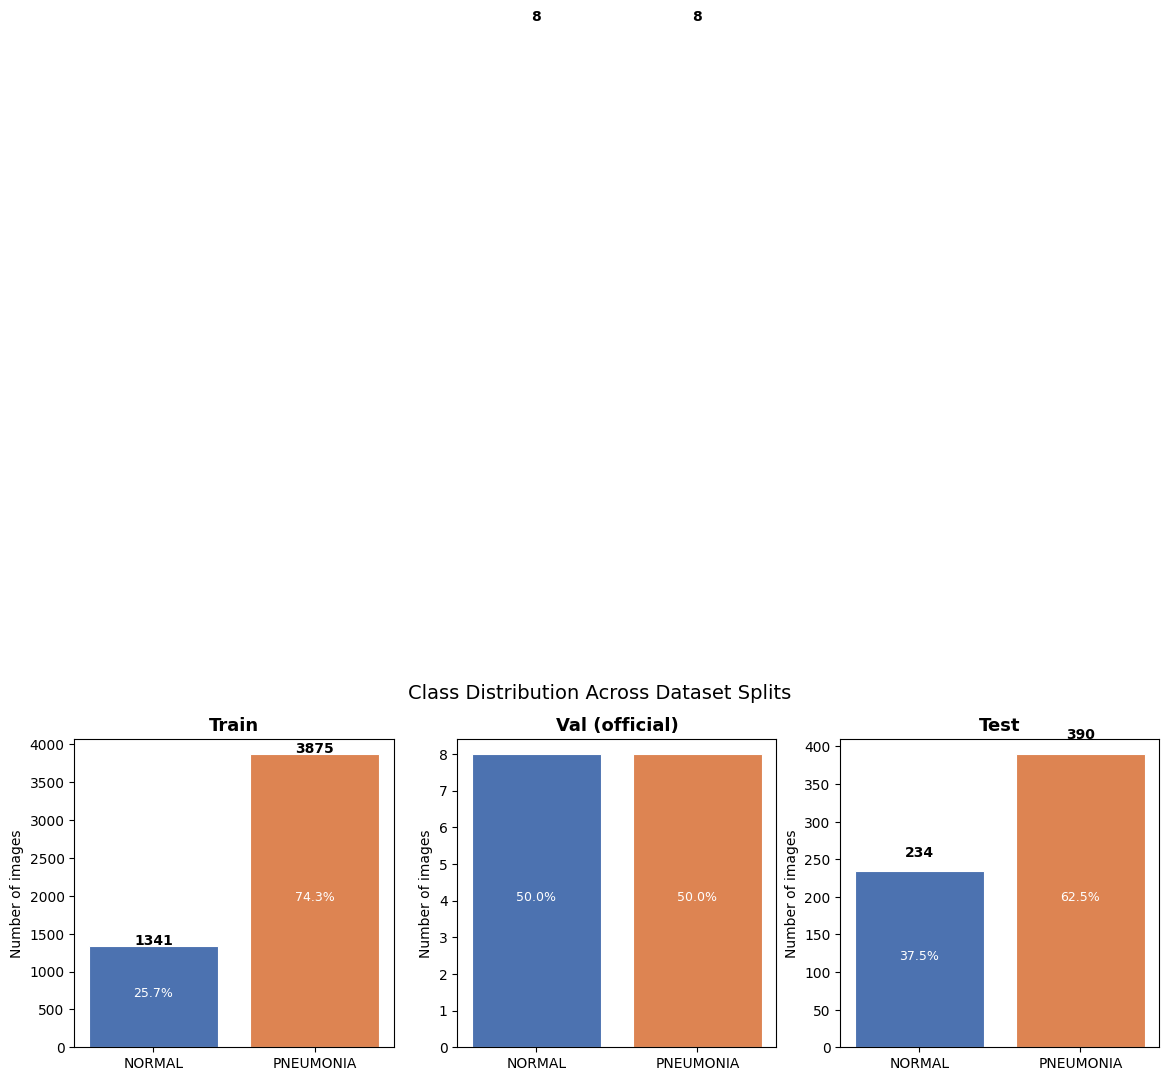


Observation: The training set is significantly imbalanced - PNEUMONIA outnumbers NORMAL
by roughly 3:1. This kind of imbalance is common in medical image datasets, especially
when the data is collected from cases already selected for clinical review.
PNEUMONIA is the MAJORITY class here, which matters when interpreting AUPRC later.

Strategy: WeightedRandomSampler balances class presentation during training.
Per-class metrics (precision, recall, F1, MCC) will be reported rather than accuracy alone.



In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ['#4C72B0', '#DD8452']

for ax, (split, counts) in zip(axes, dist.items()):
    bars = ax.bar(counts.keys(), counts.values(), color=colors, edgecolor='white', linewidth=0.8)
    ax.set_title(f'{split}', fontsize=13, fontweight='bold')
    ax.set_ylabel('Number of images')
    for bar, val in zip(bars, counts.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
                str(val), ha='center', fontsize=10, fontweight='bold')
    total = sum(counts.values())
    for bar, val in zip(bars, counts.values()):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height()/2,
                f'{100*val/total:.1f}%', ha='center', color='white', fontsize=9)

plt.suptitle('Class Distribution Across Dataset Splits', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

print("""
Observation: The training set is significantly imbalanced - PNEUMONIA outnumbers NORMAL
by roughly 3:1. This kind of imbalance is common in medical image datasets, especially
when the data is collected from cases already selected for clinical review.
PNEUMONIA is the MAJORITY class here, which matters when interpreting AUPRC later.

Strategy: WeightedRandomSampler balances class presentation during training.
Per-class metrics (precision, recall, F1, MCC) will be reported rather than accuracy alone.
""")


The table and bar charts show two things that directly shape later modeling decisions.

First, the training set is **heavily imbalanced**: PNEUMONIA accounts for roughly 74.3% of the combined train/validation pool. This is not unusual for a hospital dataset - pathological cases are naturally over-represented - but it means that accuracy is a poor summary metric. A model that always predicts PNEUMONIA would score around 74% accuracy while failing completely on NORMAL cases.

Second, the **official validation folder has only 16 images** (8 per class). Any metric computed on 16 samples has very high variance. Comparing three different architectures or tuning decision thresholds on this set is not viable.

The official test set has a different class balance: 390 out of 624 images (62.5%) are PNEUMONIA. This is lower than in the training data. Thresholds selected on the more-imbalanced validation split may push the model slightly toward over-predicting PNEUMONIA on the test set, which can inflate false positives. This is worth keeping in mind when reading the test-set results in Section 7.


### 1.2 Sample Image Inspection

Before building any pipeline, it is worth looking at a small number of actual images from each class. This takes a few seconds and can reveal a lot about what the task actually requires.


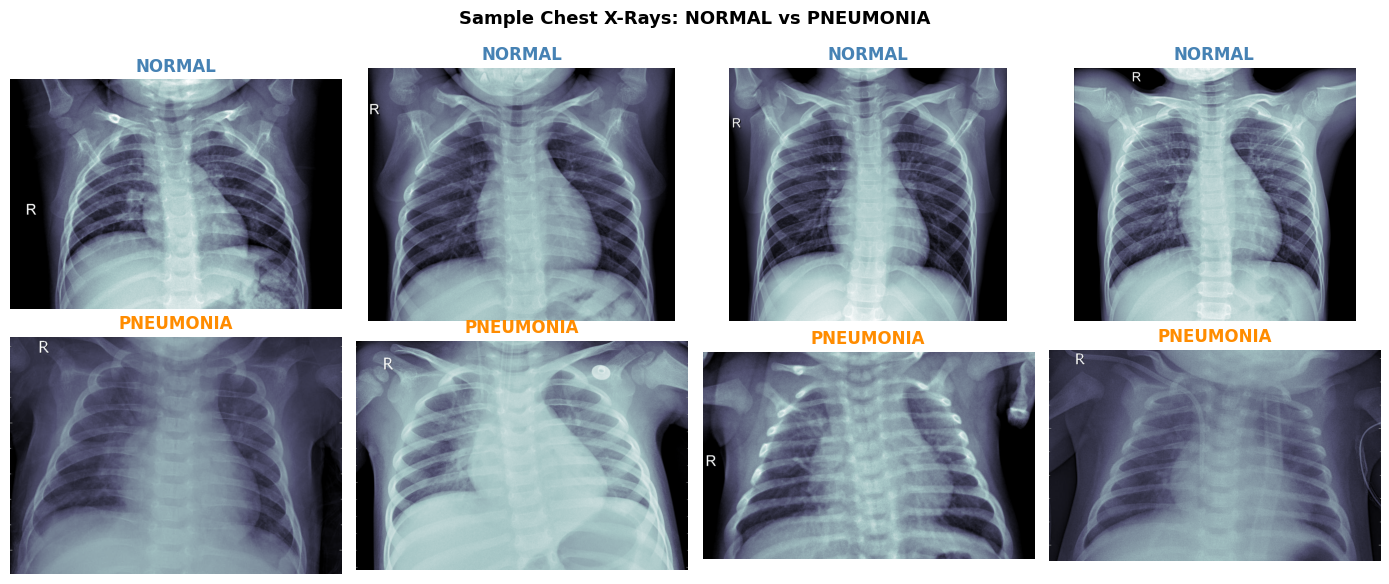

In [5]:
def load_random_samples(class_dir, n=4):
    files = list(class_dir.glob('*.jpeg')) + list(class_dir.glob('*.jpg'))
    chosen = random.sample(files, min(n, len(files)))
    return [Image.open(f).convert('L') for f in chosen]

normal_imgs    = load_random_samples(TRAIN_DIR / 'NORMAL', n=4)
pneumonia_imgs = load_random_samples(TRAIN_DIR / 'PNEUMONIA', n=4)

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for i, img in enumerate(normal_imgs):
    axes[0, i].imshow(img, cmap='bone')
    axes[0, i].set_title('NORMAL', color='steelblue', fontweight='bold')
    axes[0, i].axis('off')
for i, img in enumerate(pneumonia_imgs):
    axes[1, i].imshow(img, cmap='bone')
    axes[1, i].set_title('PNEUMONIA', color='darkorange', fontweight='bold')
    axes[1, i].axis('off')

plt.suptitle('Sample Chest X-Rays: NORMAL vs PNEUMONIA', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


Even a quick look at the samples shows that NORMAL and PNEUMONIA-labeled images are not trivially separable. Both groups have similar lung and rib structures, and the visible differences are often subtle. Some PNEUMONIA-labeled images show localized opacity or density changes, but these patterns vary across images and should not be treated as simple visual rules.

This rules out simple global rules and supports two later choices. First, transfer learning makes more sense than training from scratch: pretrained convolutional features capture texture and structural patterns that are much harder to learn on a dataset of this size. Second, the GradCAM analysis in Section 11 is a useful check - it lets us ask whether the model is actually attending to lung regions, or whether it is responding to irrelevant image properties.

No medical expertise is claimed here. These are visual observations about task difficulty, not clinical interpretations.


### 1.3 Image Size and Aspect Ratio Distribution

CNN models require a fixed input size, so it is worth checking how much variation exists in the raw images before deciding on a resizing strategy.


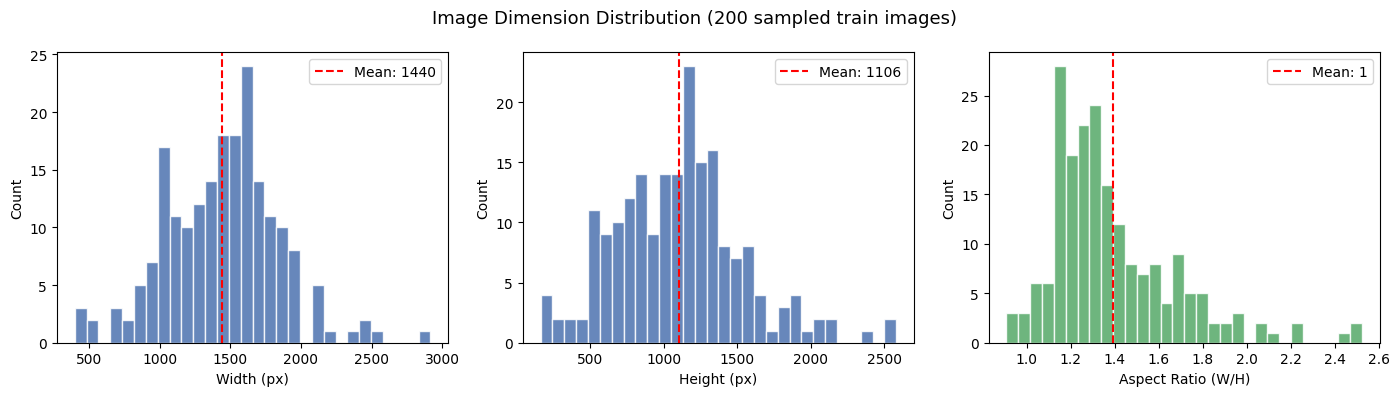

Width  - mean: 1440px, std: 397px
Height - mean: 1106px, std: 438px


In [6]:
rng = random.Random(SEED)

all_train_files = []
for cls in ['NORMAL', 'PNEUMONIA']:
    files = list((TRAIN_DIR / cls).glob('*.jpeg'))
    all_train_files += rng.sample(files, min(100, len(files)))

widths, heights, aspects = [], [], []
for f in all_train_files:
    w, h = Image.open(f).size
    widths.append(w); heights.append(h); aspects.append(w / h)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, data, label, color in zip(
    axes,
    [widths, heights, aspects],
    ['Width (px)', 'Height (px)', 'Aspect Ratio (W/H)'],
    ['#4C72B0', '#4C72B0', '#55A868']
):
    ax.hist(data, bins=30, color=color, edgecolor='white', alpha=0.85)
    ax.axvline(np.mean(data), color='red', linestyle='--', label=f'Mean: {np.mean(data):.0f}')
    ax.set_xlabel(label); ax.set_ylabel('Count'); ax.legend()

plt.suptitle('Image Dimension Distribution (200 sampled train images)', fontsize=13)
plt.tight_layout()
plt.show()
print(f'Width  - mean: {np.mean(widths):.0f}px, std: {np.std(widths):.0f}px')
print(f'Height - mean: {np.mean(heights):.0f}px, std: {np.std(heights):.0f}px')


The histograms show that widths, heights, and aspect ratios all vary substantially. Resizing to a fixed 224×224 input is necessary, but directly stretching non-square images would distort anatomy. The resize-and-center-crop approach keeps the central lung region and avoids the worst distortions.

Some distortion is still unavoidable, and this is an accepted trade-off in medical imaging transfer learning. Light augmentation during training - horizontal flips and small rotations - helps the model become less sensitive to minor variations in scale and framing.


### 1.4 Pixel Intensity Distributions per Class

If the two classes had clearly different brightness distributions, a threshold on mean pixel intensity might be a strong baseline. This section checks whether that is the case.


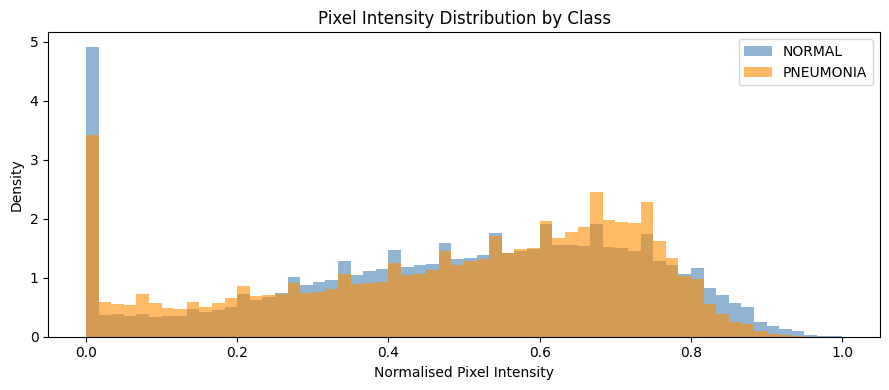

NORMAL    - mean intensity: 0.481, std: 0.247
PNEUMONIA - mean intensity: 0.485, std: 0.240


In [7]:
def mean_intensity_histogram(class_dir, n=80):
    files = random.sample(list(class_dir.glob('*.jpeg')) + list(class_dir.glob('*.jpg')), n)
    all_pixels = []
    for f in files:
        arr = np.array(Image.open(f).convert('L').resize((128, 128))) / 255.0
        all_pixels.append(arr.flatten())
    return np.concatenate(all_pixels)

normal_px    = mean_intensity_histogram(TRAIN_DIR / 'NORMAL')
pneumonia_px = mean_intensity_histogram(TRAIN_DIR / 'PNEUMONIA')

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(normal_px,    bins=60, alpha=0.6, color='steelblue',  density=True, label='NORMAL')
ax.hist(pneumonia_px, bins=60, alpha=0.6, color='darkorange', density=True, label='PNEUMONIA')
ax.set_xlabel('Normalised Pixel Intensity'); ax.set_ylabel('Density')
ax.set_title('Pixel Intensity Distribution by Class'); ax.legend()
plt.tight_layout(); plt.show()

print(f'NORMAL    - mean intensity: {normal_px.mean():.3f}, std: {normal_px.std():.3f}')
print(f'PNEUMONIA - mean intensity: {pneumonia_px.mean():.3f}, std: {pneumonia_px.std():.3f}')


The intensity histograms for NORMAL and PNEUMONIA images overlap heavily, and the printed mean values are close. This confirms that **brightness alone cannot separate the classes** - a threshold on mean intensity would perform near chance.

This is an important negative result. It rules out simple handcrafted rules and supports the decision to use CNN features instead. Whatever difference exists between the classes is spatial and structural, not a global brightness shift.

Normalization is still necessary: ResNet50 and EfficientNetB0 expect inputs normalized to ImageNet mean and standard deviation, and DenseNet-121 XRV expects the XRV range. Feeding raw pixel values would shift the input distribution away from what the pretrained weights saw, which would degrade the transferred features.


### 1.5 EDA-Driven Preprocessing Decisions

Each EDA finding above points directly to a pipeline decision. The list below makes these links explicit so that no preprocessing step looks arbitrary:

- **Class imbalance (~74.3% PNEUMONIA in training)** → `WeightedRandomSampler` balances class presentation in each batch during training; per-class precision, recall, F1, and MCC are reported alongside accuracy; three threshold strategies are evaluated on the validation set before the test set is touched; false-positive and false-negative counts are shown in all result tables. Note: for DenseNet-121 XRV, the computed `pos_weight` is below 1.0 (because PNEUMONIA is the majority class), so after clamping it becomes 1.0 - the BCE loss is effectively not class-weighted. Imbalance is handled through the sampler and threshold strategies.
- **Tiny official validation folder (16 images)** → a stratified 80/20 split is carved from the training folder; the official `val/` directory is never used for model selection or threshold tuning.
- **Variable image sizes and aspect ratios** → resize and center-crop to 224×224 for all models; this is a necessary trade-off for fixed-size batch processing.
- **Subtle visual differences between classes** → transfer learning from pretrained backbones rather than training from scratch; GradCAM in Section 11 checks whether the model attends to lung-relevant regions.
- **Near-identical class-mean intensities** → learned convolutional features instead of handcrafted intensity rules; normalization calibrated to each pretrained model's expected input scale.
- **Risk of shortcut learning** → false-positive and false-negative image inspection in Section 7.3; GradCAM qualitative check in Section 11.


---
## 2. Dataset Split and Data Loading

### Validation Strategy

The official `val/` folder contains only 16 images. Any metric computed on 16 samples has very high variance - the difference between 90% and 80% accuracy is a single image. Using this set to compare three architectures or tune decision thresholds would not be reliable.

Instead, a **stratified 80/20 split** is created from the training folder and used as the validation set for all three models. Stratification keeps the class ratio consistent in both parts of the split. The test set is left completely untouched until Section 7.

The same split indices are used for both the ImageNet pipeline and the XRV pipeline. This means all three models train and validate on the same images - the only difference is how those images are preprocessed.


### 2.1 ImageNet Pipeline (ResNet50 + EfficientNetB0)

ResNet50 and EfficientNetB0 are pretrained on ImageNet, where images are three-channel RGB, normalized to mean `[0.485, 0.456, 0.406]` and standard deviation `[0.229, 0.224, 0.225]`. To use these pretrained weights without corruption, the input format must match.

Chest X-rays are grayscale, so converting to three channels by replicating the grayscale value is a compatibility step. It is not medically meaningful - the color statistics in natural images are very different from X-ray images. This is a common baseline approach for medical imaging transfer learning, and it works well enough in practice, but it is worth acknowledging the mismatch.

Augmentation (horizontal flip, ±10° rotation, mild brightness jitter) is applied only during training to reduce overfitting. Validation and test images use only resize, center-crop, and normalization - no random transforms - to ensure unbiased probability estimates.

In [8]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Transforms
train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])

# Load full training data with both transforms
full_train_dataset_aug  = datasets.ImageFolder(TRAIN_DIR, transform=train_transform)
full_train_dataset_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_transform)
test_dataset            = datasets.ImageFolder(TEST_DIR,  transform=eval_transform)

CLASS_NAMES = full_train_dataset_aug.classes   # ['NORMAL', 'PNEUMONIA']
print('Classes:', CLASS_NAMES)
print('Class-to-index:', full_train_dataset_aug.class_to_idx)
print(f'Full training set: {len(full_train_dataset_aug)} | Test set: {len(test_dataset)}')


Classes: ['NORMAL', 'PNEUMONIA']
Class-to-index: {'NORMAL': 0, 'PNEUMONIA': 1}
Full training set: 5216 | Test set: 624


In [9]:
# Stratified 80/20 split from training folder
# We use the same indices for both ImageNet models, so comparisons are fair
all_targets = np.array(full_train_dataset_aug.targets)

# Stratified split: collect indices per class, then split each separately
rng = np.random.default_rng(SEED)
val_indices, train_indices = [], []

for cls_idx in np.unique(all_targets):
    cls_indices = np.where(all_targets == cls_idx)[0]
    cls_indices = rng.permutation(cls_indices)
    n_val = int(0.2 * len(cls_indices))
    val_indices.extend(cls_indices[:n_val].tolist())
    train_indices.extend(cls_indices[n_val:].tolist())

val_indices   = np.array(val_indices)
train_indices = np.array(train_indices)

# Augmented subset for training, eval-only subset for validation
train_subset = Subset(full_train_dataset_aug,  train_indices)
val_subset   = Subset(full_train_dataset_eval, val_indices)

# Print class distributions
def print_class_dist(indices, targets, split_name, class_names):
    counts = Counter(targets[i] for i in indices)
    total  = sum(counts.values())
    print(f"{split_name}: {total} images", end="  |  ")
    for cls_i, cls_name in enumerate(class_names):
        n = counts.get(cls_i, 0)
        print(f"{cls_name}: {n} ({100*n/total:.1f}%)", end="  ")
    print()

print("=== Class distributions after stratified split ===")
print_class_dist(train_indices, all_targets, "Train (80%)", CLASS_NAMES)
print_class_dist(val_indices,   all_targets, "Val   (20%)", CLASS_NAMES)
print_class_dist(range(len(test_dataset)), np.array(test_dataset.targets), "Test (official)", CLASS_NAMES)
print()
print(f"Train subset:  {len(train_subset)} images")
print(f"Val   subset:  {len(val_subset)} images")
print(f"Test  set:     {len(test_dataset)} images (untouched)")


=== Class distributions after stratified split ===
Train (80%): 4173 images  |  NORMAL: 1073 (25.7%)  PNEUMONIA: 3100 (74.3%)  
Val   (20%): 1043 images  |  NORMAL: 268 (25.7%)  PNEUMONIA: 775 (74.3%)  
Test (official): 624 images  |  NORMAL: 234 (37.5%)  PNEUMONIA: 390 (62.5%)  

Train subset:  4173 images
Val   subset:  1043 images
Test  set:     624 images (untouched)


In [10]:
# WeightedRandomSampler on training subset
BATCH_SIZE = 32

train_labels = [all_targets[i] for i in train_indices]
train_class_counts = Counter(train_labels)
sample_weights = [1.0 / train_class_counts[t] for t in train_labels]
sampler = WeightedRandomSampler(sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_subset,  batch_size=BATCH_SIZE, sampler=sampler,
                          num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_subset,    batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=4, pin_memory=True)

# Image paths for FN/FP analysis
test_paths = np.array([p for (p, _) in test_dataset.samples])

print(f'Train loader: {len(train_loader)} batches | Val: {len(val_loader)} | Test: {len(test_loader)}')


Train loader: 131 batches | Val: 33 | Test: 20


### 2.2 XRV Preprocessing Pipeline for DenseNet-121

DenseNet-121 from TorchXRayVision was pretrained on several large chest X-ray collections, including CheXpert, MIMIC-CXR, and the NIH ChestX-ray14 dataset. This makes it a fundamentally different starting point than an ImageNet backbone - its earlier layers already encode radiologically relevant features rather than color texture patterns from natural photographs.

To keep those pretrained representations intact, the input must follow the format used during XRV pretraining: **single-channel grayscale**, normalized to the XRV intensity range (approximately [-1024, 1024]). Using ImageNet normalization here would feed out-of-scale values to a model that was never trained on them, effectively corrupting the pretrained features.

The `XRVTransform` class applies the grayscale conversion and XRV normalization. The **same stratified split indices** used for the ImageNet pipeline (`train_indices`, `val_indices`) are reused here, so the comparison between models is fair - only the preprocessing differs, not the data.

In [11]:
# XRV-specific transform
import torchxrayvision as xrv
import torchvision.transforms as T

class XRVTransform:
    """
    Preprocessing pipeline for TorchXRayVision models.
    Converts PIL image → [1, 224, 224] tensor in [-1024, 1024].
    """
    def __init__(self, size=224, augment=False):
        self.size        = size
        self.augment     = augment
        self.to_tensor   = T.ToTensor()
        self.center_crop = xrv.datasets.XRayCenterCrop()
        self.resizer     = xrv.datasets.XRayResizer(size)
        if augment:
            self.aug = T.Compose([
                T.RandomHorizontalFlip(),
                T.RandomRotation(10),
                T.ColorJitter(brightness=0.2),
            ])

    def __call__(self, img: Image.Image):
        img = img.convert("L")
        if self.augment:
            img = self.aug(img)
        x   = self.to_tensor(img)
        x   = x * 255.0
        x   = xrv.datasets.normalize(x.numpy(), 255)
        x   = self.center_crop(x)
        x   = self.resizer(x)
        x   = torch.from_numpy(x).float()
        return x

xrv_train_transform = XRVTransform(size=224, augment=True)
xrv_eval_transform  = XRVTransform(size=224, augment=False)

# Load full training data with XRV transforms
full_train_xrv_aug  = datasets.ImageFolder(TRAIN_DIR, transform=xrv_train_transform)
full_train_xrv_eval = datasets.ImageFolder(TRAIN_DIR, transform=xrv_eval_transform)
test_dataset_xrv    = datasets.ImageFolder(TEST_DIR,  transform=xrv_eval_transform)

# Reuse exact same train/val indices from the ImageNet split
train_sub_xrv = Subset(full_train_xrv_aug,  train_indices)
val_sub_xrv   = Subset(full_train_xrv_eval, val_indices)

print(f'XRV train subset: {len(train_sub_xrv)} | val subset: {len(val_sub_xrv)}')
print(f'XRV test set:     {len(test_dataset_xrv)}')

# pos_weight from the training subset
xrv_sub_counts = Counter(all_targets[i] for i in train_indices)
pos_weight_xrv = torch.tensor(
    [xrv_sub_counts[0] / xrv_sub_counts[1]], device=DEVICE
).clamp(min=1.0)
print(f'XRV pos_weight (NORMAL/PNEUMONIA in train subset): {pos_weight_xrv.item():.3f}')

# Sampler on XRV training subset
xrv_train_labels   = [all_targets[i] for i in train_indices]
xrv_sample_weights = [1.0 / xrv_sub_counts[t] for t in xrv_train_labels]
sampler_xrv = WeightedRandomSampler(
    xrv_sample_weights, num_samples=len(xrv_sample_weights), replacement=True
)

train_loader_xrv = DataLoader(train_sub_xrv,    batch_size=BATCH_SIZE, sampler=sampler_xrv,
                               num_workers=4, pin_memory=True)
val_loader_xrv   = DataLoader(val_sub_xrv,      batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=4, pin_memory=True)
test_loader_xrv  = DataLoader(test_dataset_xrv, batch_size=BATCH_SIZE, shuffle=False,
                               num_workers=4, pin_memory=True)

print("XRV dataloaders ready.")


XRV train subset: 4173 | val subset: 1043
XRV test set:     624
XRV pos_weight (NORMAL/PNEUMONIA in train subset): 1.000
XRV dataloaders ready.


---
## 3. Model Architecture and Transfer Learning Strategy

Three models are compared, each representing a different relationship between pretraining and the target task:

- **ResNet50:** a 50-layer residual network pretrained on ImageNet. This is the primary general-purpose CNN baseline, widely used in medical imaging transfer learning studies.
- **EfficientNetB0:** uses compound scaling of depth, width, and resolution to reach competitive accuracy with a smaller parameter count. It tests whether a more efficient ImageNet-pretrained architecture performs similarly to a larger one on this task.
- **DenseNet-121 (TorchXRayVision):** pretrained on millions of chest X-ray images across several public datasets (CheXpert, MIMIC-CXR, NIH ChestX-ray14). Its earlier layers already encode chest X-ray texture and anatomy patterns, which makes it a more domain-specific starting point. Whether this translates into better classification performance needs to be confirmed empirically - that is what Section 7 shows.

### Fine-Tuning Strategy

All three models use a **two-phase approach**:

- **Phase 1 (frozen backbone)**: only the new classification head is trained at LR = 1e-3. This stabilizes the head before any pretrained weights are modified.
- **Phase 2 (unfrozen layers)**: backbone layers are unfrozen and fine-tuned at a lower learning rate (1e-4 for ResNet50/EfficientNetB0; 1e-5 for DenseNet-121 XRV).

For **DenseNet-121 XRV**, only the final DenseBlock (`denseblock4`) and the final batch normalization layer (`norm5`) are unfrozen in Phase 2. All earlier DenseNet blocks stay frozen. This is a deliberate choice: full fine-tuning on a dataset of this size risks overwriting the radiological representations in the earlier layers. Partial fine-tuning lets the model adapt to this specific task while keeping the domain-specific pretraining intact.


In [12]:
def build_resnet50(num_classes=2, freeze_backbone=True):
    model = models.resnet50(weights=ResNet50_Weights.IMAGENET1K_V2)
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
    model.fc = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(model.fc.in_features, num_classes)
    )
    return model


def build_efficientnet_b0(num_classes=2, freeze_backbone=True):
    model = models.efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False
    in_features = model.classifier[1].in_features
    model.classifier = nn.Sequential(
        nn.Dropout(0.3),
        nn.Linear(in_features, num_classes)
    )
    return model


class CXRDenseNetBinary(nn.Module):
    """
    DenseNet-121 from TorchXRayVision with a binary classification head.

    The entire pretrained backbone is frozen at initialisation. Partial
    unfreezing of denseblock4 (and norm5 if present) is performed inside
    train_densenet_xrv immediately before Phase 2, ensuring that Phase 1
    trains only the classification head at the higher learning rate (1e-3).

    Output: raw logit (use BCEWithLogitsLoss during training).
    """
    def __init__(self):
        super().__init__()
        backbone = xrv.models.DenseNet(weights="densenet121-res224-all")
        # Freeze the entire pretrained backbone at initialisation
        # train_densenet_xrv will selectively unfreeze denseblock4 and
        # norm5 immediately before Phase 2 (lr=1e-5)
        for p in backbone.parameters():
            p.requires_grad = False
        self.backbone = backbone
        self.pool = nn.AdaptiveAvgPool2d((1, 1))
        self.head = nn.Sequential(
            nn.Dropout(0.3),
            nn.Linear(1024, 1)   # DenseNet-121 produces 1024-channel feature maps
        )

    def forward(self, x):
        feats  = self.backbone.features(x)   # [B, 1024, H', W']
        feats  = self.pool(feats).squeeze(-1).squeeze(-1)   # [B, 1024]
        logit  = self.head(feats).squeeze(1)                # [B]
        return logit


def count_params(model):
    total     = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable


# Instantiate models
resnet_model   = build_resnet50(freeze_backbone=True)
effnet_model   = build_efficientnet_b0(freeze_backbone=True)
densenet_model = CXRDenseNetBinary()

for name, m in [('ResNet50', resnet_model), ('EfficientNetB0', effnet_model), ('DenseNet-121 (XRV)', densenet_model)]:
    total, trainable = count_params(m)
    print(f'{name:25s} | Total params: {total/1e6:6.2f}M | Trainable: {trainable/1e6:6.2f}M')


Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 99.7MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 87.9MB/s]


If this fails you can run `wget https://github.com/mlmed/torchxrayvision/releases/download/v1/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt -O /root/.torchxrayvision/models_data/nih-pc-chex-mimic_ch-google-openi-kaggle-densenet121-d121-tw-lr001-rot45-tr15-sc15-seed0-best.pt`
[██████████████████████████████████████████████████]
ResNet50                  | Total params:  23.51M | Trainable:   0.00M
EfficientNetB0            | Total params:   4.01M | Trainable:   0.00M
DenseNet-121 (XRV)        | Total params:   6.97M | Trainable:   0.00M


---
## 4. Training Loops

### 4.1 ResNet50 and EfficientNetB0

The training loop for the ImageNet models reflects several choices that are motivated by the data and task:

- **Label smoothing (ε = 0.1)** on `CrossEntropyLoss`: softens hard 0/1 targets to 0.05/0.95. This prevents the model from becoming overconfident and produces better-calibrated probabilities - important because those probabilities are later used to select decision thresholds.
- **AdamW with weight_decay = 1e-4**: weight decay regularizes the model by penalizing large weights. AdamW applies it correctly, without interference from the adaptive gradient scaling in Adam.
- **CosineAnnealingLR**: the learning rate decays smoothly over each phase rather than dropping abruptly. This generally produces more stable convergence at the end of training.
- **Early stopping on validation MCC** (patience = 5): under class imbalance, accuracy can look high even when NORMAL recall is poor. MCC accounts for TP, TN, FP, and FN simultaneously, so a model that ignores the minority class cannot achieve a high MCC. The best-MCC checkpoint is restored after training.
- **WeightedRandomSampler**: each batch is drawn so that NORMAL and PNEUMONIA images appear roughly equally often, counteracting the ~3:1 imbalance in the training set.


In [13]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)
    return running_loss / total, 100. * correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()
    running_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels, all_probs = [], [], []
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)
        running_loss += loss.item() * images.size(0)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())
    val_mcc = matthews_corrcoef(all_labels, all_preds)
    return running_loss / total, 100. * correct / total, all_preds, all_labels, all_probs, val_mcc


def train_model(model, model_name, train_loader, val_loader, device,
                phase1_epochs=3, phase2_epochs=10,
                lr_head=1e-3, lr_finetune=1e-4,
                early_stop_patience=5):
    """
    Two-phase training with early stopping on validation MCC.
      Phase 1: freeze backbone, train head only  (lr_head)
      Phase 2: unfreeze all, fine-tune end-to-end (lr_finetune)
    MCC is used instead of accuracy because it is more informative for
    imbalanced binary classification: it penalises both FN and FP relative
    to the class sizes, unlike accuracy which can be dominated by the majority class.
    """
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    history   = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': [], 'val_mcc': []}
    best_val_mcc, best_state = -1.0, None
    no_improve = 0

    for phase, n_epochs, lr in [
        ('Phase 1 (head only)',      phase1_epochs, lr_head),
        ('Phase 2 (full fine-tune)', phase2_epochs, lr_finetune)
    ]:
        if phase.startswith('Phase 2'):
            for param in model.parameters():
                param.requires_grad = True
            print(f'\n── Unfreezing backbone for {phase} ──')
            no_improve = 0

        optimizer = optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=lr, weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

        print(f'\n[{model_name}] {phase}')
        for epoch in range(1, n_epochs + 1):
            tr_loss, tr_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
            vl_loss, vl_acc, _, _, _, vl_mcc = evaluate(model, val_loader, criterion, device)
            scheduler.step()
            history['train_loss'].append(tr_loss)
            history['val_loss'].append(vl_loss)
            history['train_acc'].append(tr_acc)
            history['val_acc'].append(vl_acc)
            history['val_mcc'].append(vl_mcc)
            improved = '✓' if vl_mcc > best_val_mcc else ' '
            print(f'  {improved} Epoch {epoch:02d} | '
                  f'Train loss: {tr_loss:.4f} acc: {tr_acc:.2f}% | '
                  f'Val loss: {vl_loss:.4f} acc: {vl_acc:.2f}% | Val MCC: {vl_mcc:.4f}')
            if vl_mcc > best_val_mcc:
                best_val_mcc = vl_mcc
                best_state   = {k: v.clone() for k, v in model.state_dict().items()}
                no_improve   = 0
            else:
                no_improve += 1
                if no_improve >= early_stop_patience:
                    print(f'  Early stopping at epoch {epoch} (patience={early_stop_patience})')
                    break

    model.load_state_dict(best_state)
    print(f'\nBest val MCC for {model_name}: {best_val_mcc:.4f}')
    return model, history


### 4.2 Training Function for DenseNet-121 (XRV)

The DenseNet head outputs a single logit, so **`BCEWithLogitsLoss`** is used instead of cross-entropy. A `pos_weight` is computed from the training subset as `NORMAL_count / PNEUMONIA_count`. However, because PNEUMONIA is the **majority class**, this ratio is below 1.0. After clamping with `min=1.0`, the effective `pos_weight` is **1.0**, so the loss is not additionally class-weighted. Class imbalance is handled through `WeightedRandomSampler`, per-class metrics, validation-based threshold selection, and explicit false-positive/false-negative analysis - not through loss weighting.

Training uses two phases:

- **Phase 1 (head only, LR = 1e-3, 5 epochs)**: the entire backbone is frozen. Only the binary classification head is trained. A higher learning rate is safe here because no pretrained weights are touched.
- **Phase 2 (head + denseblock4 + norm5, LR = 1e-5, up to 10 epochs)**: the final DenseBlock and final batch normalization layer are unfrozen immediately before Phase 2 begins and fine-tuned at a very small learning rate. All earlier layers remain frozen. The small LR is intentional - it allows task-specific adaptation without overwriting the radiological knowledge encoded in the earlier XRV layers.

Early stopping monitors **validation AUROC** for DenseNet. AUROC is threshold-independent, so it is a reliable checkpoint criterion at a stage where no decision threshold has yet been selected. The best checkpoint is restored at the end of training.


In [14]:
def train_one_epoch_bce(model, loader, criterion, optimizer, device):
    model.train()
    running_loss, tp, tn, fp, fn = 0.0, 0, 0, 0, 0
    for images, labels in loader:
        images = images.to(device)
        labels = labels.float().to(device)
        optimizer.zero_grad()
        logits = model(images)
        loss   = criterion(logits, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * images.size(0)
        preds  = (torch.sigmoid(logits) >= 0.5).long()
        y_int  = labels.long()
        tp += ((preds == 1) & (y_int == 1)).sum().item()
        tn += ((preds == 0) & (y_int == 0)).sum().item()
        fp += ((preds == 1) & (y_int == 0)).sum().item()
        fn += ((preds == 0) & (y_int == 1)).sum().item()
    denom = (tp+fp)*(tp+fn)*(tn+fp)*(tn+fn)
    mcc   = (tp*tn - fp*fn) / math.sqrt(denom) if denom > 0 else 0.0
    return running_loss / max(tp + tn + fp + fn, 1), mcc


@torch.no_grad()
def evaluate_bce(model, loader, criterion, device):
    model.eval()
    running_loss, total = 0.0, 0
    all_probs, all_labels = [], []
    for images, labels in loader:
        images = images.to(device)
        labels_f = labels.float().to(device)
        logits   = model(images)
        loss     = criterion(logits, labels_f)
        running_loss += loss.item() * images.size(0)
        total        += images.size(0)
        probs = torch.sigmoid(logits).cpu().numpy()
        all_probs.extend(probs)
        all_labels.extend(labels.numpy())
    return running_loss / max(total, 1), np.array(all_probs), np.array(all_labels).astype(int)


def train_densenet_xrv(model, train_loader, val_loader, device, pos_weight,
                        head_epochs=5, finetune_epochs=10, lr_head=1e-3,
                        lr_finetune=1e-5, early_stop_patience=5):
    """
    Two-phase training for XRV DenseNet:
      Phase 1: head only, backbone entirely frozen (lr_head)
      Phase 2: head + last DenseBlock + norm5 unfrozen (lr_finetune, very small)
    Early stopping on validation AUROC.
    """
    model     = model.to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    history   = {'train_mcc': [], 'val_loss': [], 'val_auroc': []}
    best_val_auroc = 0.0
    best_state     = None
    no_improve     = 0

    for phase, n_epochs, lr, extra_params in [
        ('Phase 1 (head only)',   head_epochs,    lr_head,     []),
        ('Phase 2 (partial ft)',  finetune_epochs, lr_finetune,
         list(model.backbone.features.denseblock4.parameters()) +
         (list(model.backbone.features.norm5.parameters())
          if hasattr(model.backbone.features, 'norm5') else [])),
    ]:
        # In Phase 2 unfreeze backbone last block
        if phase.startswith('Phase 2'):
            for p in model.backbone.features.denseblock4.parameters():
                p.requires_grad = True
            if hasattr(model.backbone.features, 'norm5'):
                for p in model.backbone.features.norm5.parameters():
                    p.requires_grad = True
            no_improve = 0
            print(f'\n── Partially unfreezing DenseBlock4 + norm5 for {phase} ──')

        optimizer = optim.AdamW(
            filter(lambda p: p.requires_grad, model.parameters()),
            lr=lr, weight_decay=1e-4
        )
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=n_epochs)

        print(f'\n[DenseNet-121 XRV] {phase} ({n_epochs} epochs, lr={lr:.0e})')
        for epoch in range(1, n_epochs + 1):
            tr_loss, tr_mcc = train_one_epoch_bce(model, train_loader, criterion, optimizer, device)
            va_loss, va_probs, va_labels = evaluate_bce(model, val_loader, criterion, device)
            scheduler.step()
            va_auroc = roc_auc_score(va_labels, va_probs)
            va_auprc = average_precision_score(va_labels, va_probs)
            history['train_mcc'].append(tr_mcc)
            history['val_loss'].append(va_loss)
            history['val_auroc'].append(va_auroc)
            lr_now   = optimizer.param_groups[0]['lr']
            improved = '✓' if va_auroc > best_val_auroc else ' '
            print(f'  {improved} Epoch {epoch:02d} | train_mcc: {tr_mcc:.4f} | '
                  f'val_loss: {va_loss:.4f} | val_auroc: {va_auroc:.4f} | val_auprc: {va_auprc:.4f} | lr: {lr_now:.2e}')
            if va_auroc > best_val_auroc + 1e-4:
                best_val_auroc = va_auroc
                best_state     = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                no_improve     = 0
            else:
                no_improve += 1
                if no_improve >= early_stop_patience:
                    print(f'  Early stopping at epoch {epoch}')
                    break

    model.load_state_dict(best_state)
    model.to(device)
    print(f'\nBest val AUROC for DenseNet-121 XRV: {best_val_auroc:.4f}')
    return model, history


## 5. Training All Models

The three models are trained sequentially. Training each model takes time, so checkpoints are saved to disk immediately after training - this allows the evaluation cells to reload the best weights without rerunning training.

The training output below shows per-epoch validation MCC (ResNet50 and EfficientNetB0) and validation AUROC (DenseNet-121 XRV), along with early stopping events. These logs are informative: they show whether performance improved steadily, stalled early, or showed signs of overfitting.


In [15]:
# Train ResNet50
resnet_model = build_resnet50(freeze_backbone=True)
resnet_model, resnet_history = train_model(
    resnet_model, 'ResNet50', train_loader, val_loader, DEVICE,
    phase1_epochs=3, phase2_epochs=10, early_stop_patience=5
)
torch.save(resnet_model.state_dict(), 'resnet50_best.pth')



[ResNet50] Phase 1 (head only)
  ✓ Epoch 01 | Train loss: 0.4261 acc: 87.13% | Val loss: 0.3495 acc: 91.18% | Val MCC: 0.8031
  ✓ Epoch 02 | Train loss: 0.3366 acc: 92.81% | Val loss: 0.3151 acc: 93.58% | Val MCC: 0.8470
    Epoch 03 | Train loss: 0.3328 acc: 92.98% | Val loss: 0.3200 acc: 93.10% | Val MCC: 0.8390

── Unfreezing backbone for Phase 2 (full fine-tune) ──

[ResNet50] Phase 2 (full fine-tune)
  ✓ Epoch 01 | Train loss: 0.2843 acc: 95.69% | Val loss: 0.2545 acc: 97.32% | Val MCC: 0.9314
    Epoch 02 | Train loss: 0.2548 acc: 97.48% | Val loss: 0.2543 acc: 97.22% | Val MCC: 0.9311
  ✓ Epoch 03 | Train loss: 0.2424 acc: 98.08% | Val loss: 0.2491 acc: 97.32% | Val MCC: 0.9333
  ✓ Epoch 04 | Train loss: 0.2300 acc: 98.73% | Val loss: 0.2381 acc: 98.27% | Val MCC: 0.9564
    Epoch 05 | Train loss: 0.2233 acc: 99.23% | Val loss: 0.2392 acc: 97.89% | Val MCC: 0.9472
    Epoch 06 | Train loss: 0.2229 acc: 99.21% | Val loss: 0.2579 acc: 97.03% | Val MCC: 0.9271
    Epoch 07 | Train

In [16]:
# Train EfficientNetB0
effnet_model = build_efficientnet_b0(freeze_backbone=True)
effnet_model, effnet_history = train_model(
    effnet_model, 'EfficientNetB0', train_loader, val_loader, DEVICE,
    phase1_epochs=3, phase2_epochs=10, early_stop_patience=5
)
torch.save(effnet_model.state_dict(), 'efficientnet_b0_best.pth')



[EfficientNetB0] Phase 1 (head only)
  ✓ Epoch 01 | Train loss: 0.3863 acc: 89.82% | Val loss: 0.3262 acc: 93.38% | Val MCC: 0.8439
    Epoch 02 | Train loss: 0.3261 acc: 93.51% | Val loss: 0.3443 acc: 91.56% | Val MCC: 0.8113
    Epoch 03 | Train loss: 0.3188 acc: 93.82% | Val loss: 0.3384 acc: 92.04% | Val MCC: 0.8204

── Unfreezing backbone for Phase 2 (full fine-tune) ──

[EfficientNetB0] Phase 2 (full fine-tune)
  ✓ Epoch 01 | Train loss: 0.2908 acc: 95.76% | Val loss: 0.2988 acc: 94.82% | Val MCC: 0.8776
  ✓ Epoch 02 | Train loss: 0.2653 acc: 96.98% | Val loss: 0.2647 acc: 96.64% | Val MCC: 0.9169
  ✓ Epoch 03 | Train loss: 0.2526 acc: 97.84% | Val loss: 0.2563 acc: 97.41% | Val MCC: 0.9351
  ✓ Epoch 04 | Train loss: 0.2468 acc: 97.92% | Val loss: 0.2428 acc: 97.79% | Val MCC: 0.9443
  ✓ Epoch 05 | Train loss: 0.2316 acc: 98.80% | Val loss: 0.2350 acc: 98.27% | Val MCC: 0.9564
    Epoch 06 | Train loss: 0.2268 acc: 98.99% | Val loss: 0.2357 acc: 97.89% | Val MCC: 0.9466
  ✓ Epoc

In [17]:
# Train DenseNet-121 (XRV) - partial fine-tuning
densenet_model = CXRDenseNetBinary()
densenet_model, densenet_history = train_densenet_xrv(
    densenet_model, train_loader_xrv, val_loader_xrv, DEVICE,
    pos_weight=pos_weight_xrv,
    head_epochs=5, finetune_epochs=10,
    lr_head=1e-3, lr_finetune=1e-5,
    early_stop_patience=5
)
torch.save(densenet_model.state_dict(), 'densenet121_xrv_best.pth')



[DenseNet-121 XRV] Phase 1 (head only) (5 epochs, lr=1e-03)
  ✓ Epoch 01 | train_mcc: 0.7261 | val_loss: 0.2523 | val_auroc: 0.9841 | val_auprc: 0.9947 | lr: 9.05e-04
  ✓ Epoch 02 | train_mcc: 0.8400 | val_loss: 0.1684 | val_auroc: 0.9870 | val_auprc: 0.9956 | lr: 6.55e-04
  ✓ Epoch 03 | train_mcc: 0.8419 | val_loss: 0.1621 | val_auroc: 0.9884 | val_auprc: 0.9961 | lr: 3.45e-04
  ✓ Epoch 04 | train_mcc: 0.8401 | val_loss: 0.1635 | val_auroc: 0.9891 | val_auprc: 0.9964 | lr: 9.55e-05
  ✓ Epoch 05 | train_mcc: 0.8672 | val_loss: 0.1690 | val_auroc: 0.9891 | val_auprc: 0.9964 | lr: 0.00e+00

── Partially unfreezing DenseBlock4 + norm5 for Phase 2 (partial ft) ──

[DenseNet-121 XRV] Phase 2 (partial ft) (10 epochs, lr=1e-05)
  ✓ Epoch 01 | train_mcc: 0.8510 | val_loss: 0.1431 | val_auroc: 0.9897 | val_auprc: 0.9966 | lr: 9.76e-06
    Epoch 02 | train_mcc: 0.8548 | val_loss: 0.1616 | val_auroc: 0.9895 | val_auprc: 0.9965 | lr: 9.05e-06
  ✓ Epoch 03 | train_mcc: 0.8620 | val_loss: 0.1454 | 

## 5.1 Training Curves

Training curves help diagnose whether training worked well. A gap between training and validation loss that grows over epochs suggests overfitting. Curves that plateau before the last epoch confirm that early stopping was effective. The vertical dashed line marks the Phase 1 → Phase 2 transition for ResNet50 and EfficientNetB0; a drop or improvement at that point shows that fine-tuning the backbone was beneficial.

For DenseNet-121 XRV, the two phases use different metrics (train MCC and validation AUROC), so they are plotted separately.


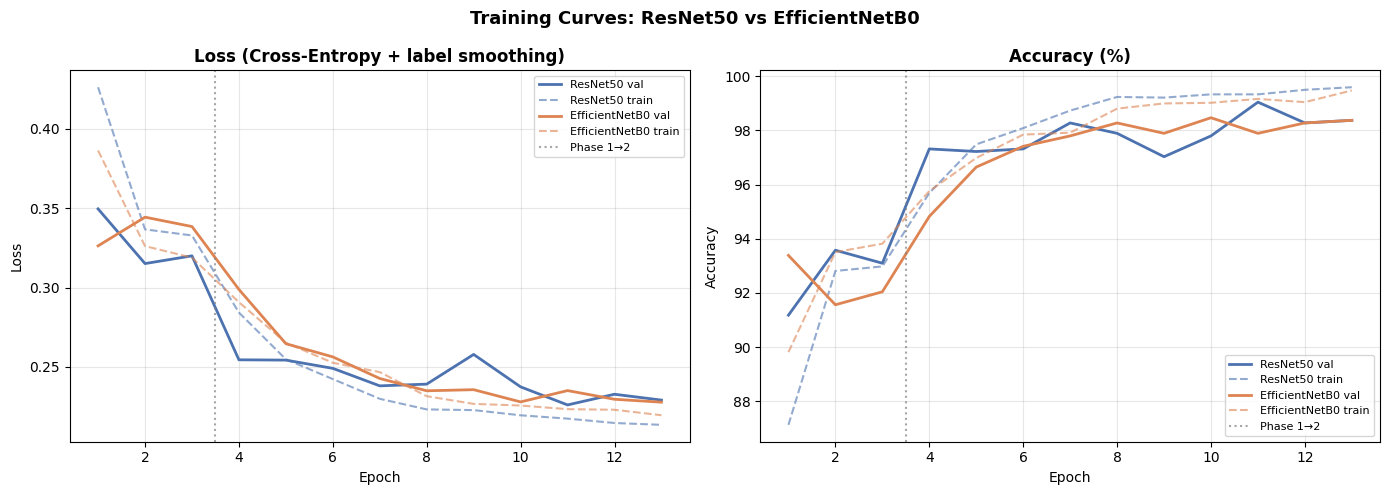

In [18]:
def plot_training_curves(histories: dict, phase1_epochs=3):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    colors = ['#4C72B0', '#DD8452']

    for (name, hist), color in zip(histories.items(), colors):
        epochs = range(1, len(hist['train_loss']) + 1)
        axes[0].plot(epochs, hist['val_loss'],   label=f'{name} val',   color=color, linewidth=2)
        axes[0].plot(epochs, hist['train_loss'], label=f'{name} train', color=color, linewidth=1.5, linestyle='--', alpha=0.6)
        axes[1].plot(epochs, hist['val_acc'],    label=f'{name} val',   color=color, linewidth=2)
        axes[1].plot(epochs, hist['train_acc'],  label=f'{name} train', color=color, linewidth=1.5, linestyle='--', alpha=0.6)

    for ax in axes:
        ax.axvline(phase1_epochs + 0.5, color='gray', linestyle=':', alpha=0.7, label='Phase 1→2')
        ax.set_xlabel('Epoch'); ax.legend(fontsize=8); ax.grid(True, alpha=0.3)

    axes[0].set_title('Loss (Cross-Entropy + label smoothing)', fontweight='bold')
    axes[0].set_ylabel('Loss')
    axes[1].set_title('Accuracy (%)', fontweight='bold')
    axes[1].set_ylabel('Accuracy')

    plt.suptitle('Training Curves: ResNet50 vs EfficientNetB0', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()

plot_training_curves({'ResNet50': resnet_history, 'EfficientNetB0': effnet_history}, phase1_epochs=3)


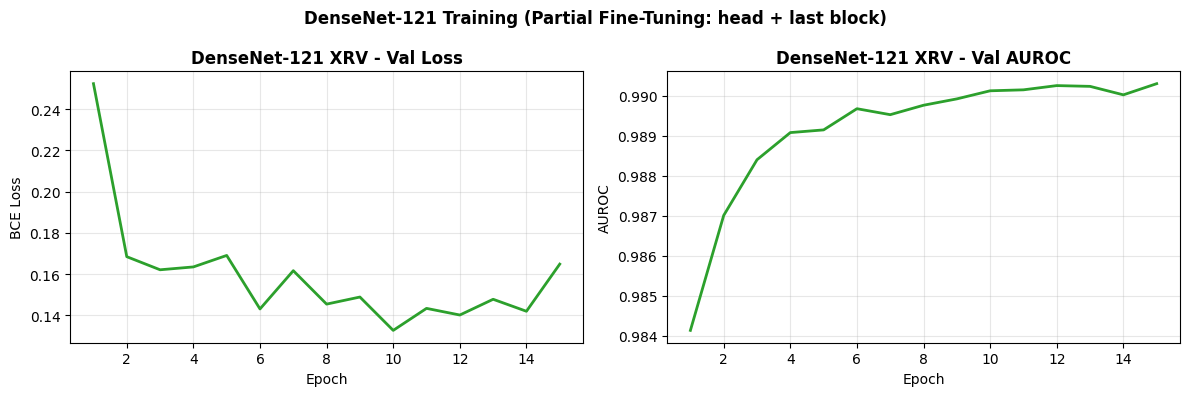

In [19]:
# DenseNet-121 (XRV) training curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = range(1, len(densenet_history['val_loss']) + 1)

axes[0].plot(epochs, densenet_history['val_loss'], color='#2CA02C', linewidth=2)
axes[0].set_title('DenseNet-121 XRV - Val Loss', fontweight='bold')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE Loss'); axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs, densenet_history['val_auroc'], color='#2CA02C', linewidth=2)
axes[1].set_title('DenseNet-121 XRV - Val AUROC', fontweight='bold')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('AUROC'); axes[1].grid(True, alpha=0.3)

plt.suptitle('DenseNet-121 Training (Partial Fine-Tuning: head + last block)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()


---
## 6. Threshold Selection

The default threshold of 0.5 treats all classification errors as equally costly and assumes perfectly calibrated probabilities. Neither of these holds in general, especially in a screening-style image classification task where a missed PNEUMONIA-labeled image can be more serious than a NORMAL-labeled image being incorrectly flagged.

Thresholds are selected **only on the validation set**, then applied exactly once to the test set. Three strategies are evaluated, covering different operating priorities:

- **Strategy A (maximize PNEUMONIA F1-score):** this threshold best balances precision and recall for the positive class. It is useful as a reference, but it is not truly balanced because it optimizes only the PNEUMONIA-class F1-score and does not directly penalize weak NORMAL recall.

- **Strategy B (screening-oriented threshold: PNEUMONIA recall ≥ 0.97, then max MCC):** this threshold aims to catch at least 97% of PNEUMONIA-labeled validation images. Among all thresholds that satisfy this recall constraint, the one with the best MCC is selected. This accepts more false positives to reduce the number of PNEUMONIA-labeled images predicted as NORMAL.

- **Strategy C (maximize validation MCC):** MCC accounts for TP, TN, FP, and FN simultaneously. It is the most balanced single-number criterion under class imbalance because it is not dominated by one class. This is the primary operating point for balanced model selection.

All thresholds are finalized on the validation set before the test set is opened.

In [20]:
@torch.no_grad()
def get_probs(model, loader, device, model_type='softmax'):
    """Collect probabilities and labels from a loader."""
    model.eval()
    all_probs, all_labels = [], []
    for images, labels in loader:
        images = images.to(device)
        if model_type == 'softmax':
            probs = torch.softmax(model(images), dim=1)[:, 1].cpu().numpy()
        else:
            probs = torch.sigmoid(model(images)).cpu().numpy()
        all_probs.extend(probs)
        all_labels.extend(labels.numpy())
    return np.array(all_probs), np.array(all_labels).astype(int)


def select_thresholds(probs, labels, model_name, min_recall=0.97):
    """
    Returns:
      thr_f1    : threshold maximising PNEUMONIA F1-score (Strategy A)
      thr_recall: threshold achieving recall >= min_recall, then maximising MCC (Strategy B)
      thr_mcc   : threshold maximising MCC directly (Strategy C)
    """
    precision, recall, thresholds = precision_recall_curve(labels, probs)

    # Strategy A: max PNEUMONIA F1-score
    f1 = 2 * precision[:-1] * recall[:-1] / (precision[:-1] + recall[:-1] + 1e-12)
    best_f1_i  = np.argmax(f1)
    thr_f1     = thresholds[best_f1_i]

    # Strategy B & C: sweep MCC over all candidate thresholds (same loop)
    mcc_scores = []
    for thr in thresholds:
        preds = (probs >= thr).astype(int)
        mcc_scores.append(matthews_corrcoef(labels, preds))
    mcc_scores = np.array(mcc_scores)

    # Strategy B: recall >= min_recall, then max MCC
    eligible = recall[:-1] >= min_recall
    if eligible.any():
        thr_recall = thresholds[np.argmax(mcc_scores * eligible.astype(float))]
    else:
        thr_recall = thresholds[np.argmax(recall[:-1])]

    # Strategy C: max MCC directly
    thr_mcc = thresholds[np.argmax(mcc_scores)]

    print(f"\n{model_name} threshold selection (val set):")
    print(f"  Strategy A (max PNEUMONIA F1):   thr={thr_f1:.3f} | F1={f1[best_f1_i]:.4f} | "
          f"Precision={precision[best_f1_i]:.3f} | Recall={recall[best_f1_i]:.3f}")

    preds_b  = (probs >= thr_recall).astype(int)
    mcc_b    = matthews_corrcoef(labels, preds_b)
    r_idx_b  = np.searchsorted(thresholds, thr_recall, side='right') - 1
    recall_b = recall[:-1][r_idx_b] if 0 <= r_idx_b < len(recall)-1 else np.nan
    print(f"  Strategy B (recall>={min_recall}):  thr={thr_recall:.3f} | MCC={mcc_b:.4f} | "
          f"PNEUMONIA recall≈{recall_b:.3f}")

    best_mcc_val = mcc_scores[np.argmax(mcc_scores)]
    print(f"  Strategy C (max MCC):            thr={thr_mcc:.3f} | val MCC={best_mcc_val:.4f}")

    return thr_f1, thr_recall, thr_mcc


# Val probabilities
print("Getting validation probabilities for threshold selection:")
resnet_val_probs,   resnet_val_labels   = get_probs(resnet_model,   val_loader,     DEVICE, 'softmax')
effnet_val_probs,   effnet_val_labels   = get_probs(effnet_model,   val_loader,     DEVICE, 'softmax')
densenet_val_probs, densenet_val_labels = get_probs(densenet_model, val_loader_xrv, DEVICE, 'sigmoid')

resnet_thr_f1,   resnet_thr_recall,   resnet_thr_mcc   = select_thresholds(resnet_val_probs,   resnet_val_labels,   'ResNet50')
effnet_thr_f1,   effnet_thr_recall,   effnet_thr_mcc   = select_thresholds(effnet_val_probs,   effnet_val_labels,   'EfficientNetB0')
densenet_thr_f1, densenet_thr_recall, densenet_thr_mcc = select_thresholds(densenet_val_probs, densenet_val_labels, 'DenseNet-121 XRV')


Getting validation probabilities for threshold selection:

ResNet50 threshold selection (val set):
  Strategy A (max PNEUMONIA F1):   thr=0.443 | F1=0.9935 | Precision=0.995 | Recall=0.992
  Strategy B (recall>=0.97):  thr=0.511 | MCC=0.9752 | PNEUMONIA recall≈0.990
  Strategy C (max MCC):            thr=0.511 | val MCC=0.9752

EfficientNetB0 threshold selection (val set):
  Strategy A (max PNEUMONIA F1):   thr=0.169 | F1=0.9936 | Precision=0.989 | Recall=0.999
  Strategy B (recall>=0.97):  thr=0.263 | MCC=0.9750 | PNEUMONIA recall≈0.992
  Strategy C (max MCC):            thr=0.263 | val MCC=0.9750

DenseNet-121 XRV threshold selection (val set):
  Strategy A (max PNEUMONIA F1):   thr=0.367 | F1=0.9740 | Precision=0.980 | Recall=0.968
  Strategy B (recall>=0.97):  thr=0.319 | MCC=0.8978 | PNEUMONIA recall≈0.970
  Strategy C (max MCC):            thr=0.367 | val MCC=0.9011


---
## 7. Final Evaluation on Test Set

The test set is used **once**, here. All threshold choices were finalized on the validation set; nothing is adjusted based on test-set results.

Each model is evaluated under all three threshold strategies. Results include accuracy, AUROC, AUPRC, MCC, per-class precision/recall/F1, false negatives, and false positives. The goal is not to find one best number but to understand how each model behaves at different operating points.

The metrics that matter most for this task are **MCC** (overall balance across both classes), **NORMAL recall** (false-positive control: how often the model correctly identifies NORMAL-labeled images), and **false negative count** (PNEUMONIA-labeled images predicted as NORMAL - the most serious screening error in this task). High PNEUMONIA recall alone is not sufficient: a model that predicts PNEUMONIA for every image achieves perfect PNEUMONIA recall but is useless in practice.


In [21]:
# Test probabilities
resnet_test_probs,   resnet_test_labels   = get_probs(resnet_model,   test_loader,     DEVICE, 'softmax')
effnet_test_probs,   effnet_test_labels   = get_probs(effnet_model,   test_loader,     DEVICE, 'softmax')
densenet_test_probs, densenet_test_labels = get_probs(densenet_model, test_loader_xrv, DEVICE, 'sigmoid')

# Pack results: each model carries probs, labels, and all three thresholds
test_results = {
    'ResNet50': {
        'probs':      resnet_test_probs,
        'labels':     resnet_test_labels,
        'thr_f1':     resnet_thr_f1,
        'thr_recall': resnet_thr_recall,
        'thr_mcc':    resnet_thr_mcc,
    },
    'EfficientNetB0': {
        'probs':      effnet_test_probs,
        'labels':     effnet_test_labels,
        'thr_f1':     effnet_thr_f1,
        'thr_recall': effnet_thr_recall,
        'thr_mcc':    effnet_thr_mcc,
    },
    'DenseNet-121 (XRV)': {
        'probs':      densenet_test_probs,
        'labels':     densenet_test_labels,
        'thr_f1':     densenet_thr_f1,
        'thr_recall': densenet_thr_recall,
        'thr_mcc':    densenet_thr_mcc,
    },
}

for name, res in test_results.items():
    res['preds_f1']     = (res['probs'] >= res['thr_f1']).astype(int)
    res['preds_recall'] = (res['probs'] >= res['thr_recall']).astype(int)
    res['preds_mcc']    = (res['probs'] >= res['thr_mcc']).astype(int)

CLASS_NAMES = ['NORMAL', 'PNEUMONIA']
print("Test probabilities collected. Ready for evaluation.")


Test probabilities collected. Ready for evaluation.


In [22]:
def full_metrics(labels, preds, probs, class_names):
    """Compute a comprehensive metrics dict."""
    p, r, f, _ = precision_recall_fscore_support(labels, preds, average=None, labels=[0, 1])
    fpr_v, tpr_v, _ = roc_curve(labels, probs)
    return {
        'Accuracy':          round(accuracy_score(labels, preds) * 100, 2),
        'AUROC':             round(roc_auc_score(labels, probs), 4),
        'AUPRC':             round(average_precision_score(labels, probs), 4),
        'MCC':               round(matthews_corrcoef(labels, preds), 4),
        'Precision-NORMAL':  round(p[0], 4),
        'Recall-NORMAL':     round(r[0], 4),
        'F1-NORMAL':         round(f[0], 4),
        'Precision-PNEUMONIA': round(p[1], 4),
        'Recall-PNEUMONIA':  round(r[1], 4),
        'F1-PNEUMONIA':      round(f[1], 4),
        'False Negatives':   int(np.sum((labels == 1) & (preds == 0))),
        'False Positives':   int(np.sum((labels == 0) & (preds == 1))),
    }

print("\n" + "="*70)
print("STRATEGY A: Threshold maximising PNEUMONIA F1-score")
print("="*70)
for name, res in test_results.items():
    m = full_metrics(res['labels'], res['preds_f1'], res['probs'], CLASS_NAMES)
    print(f"\n{name} (thr={res['thr_f1']:.3f})")
    print(classification_report(res['labels'], res['preds_f1'], target_names=CLASS_NAMES, digits=4))
    print(f"  AUROC={m['AUROC']}  AUPRC={m['AUPRC']}  MCC={m['MCC']}  FN={m['False Negatives']}  FP={m['False Positives']}")

print("\n" + "="*70)
print("STRATEGY B: Threshold achieving PNEUMONIA recall >= 0.97 (screening regime)")
print("="*70)
for name, res in test_results.items():
    m = full_metrics(res['labels'], res['preds_recall'], res['probs'], CLASS_NAMES)
    print(f"\n{name} (thr={res['thr_recall']:.3f})")
    print(classification_report(res['labels'], res['preds_recall'], target_names=CLASS_NAMES, digits=4))
    print(f"  AUROC={m['AUROC']}  AUPRC={m['AUPRC']}  MCC={m['MCC']}  FN={m['False Negatives']}  FP={m['False Positives']}")

print("\n" + "="*70)
print("STRATEGY C: Threshold maximising validation MCC")
print("="*70)
for name, res in test_results.items():
    m = full_metrics(res['labels'], res['preds_mcc'], res['probs'], CLASS_NAMES)
    print(f"\n{name} (thr={res['thr_mcc']:.3f})")
    print(classification_report(res['labels'], res['preds_mcc'], target_names=CLASS_NAMES, digits=4))
    print(f"  AUROC={m['AUROC']}  AUPRC={m['AUPRC']}  MCC={m['MCC']}  FN={m['False Negatives']}  FP={m['False Positives']}")



STRATEGY A: Threshold maximising PNEUMONIA F1-score

ResNet50 (thr=0.443)
              precision    recall  f1-score   support

      NORMAL     0.9932    0.6282    0.7696       234
   PNEUMONIA     0.8172    0.9974    0.8984       390

    accuracy                         0.8590       624
   macro avg     0.9052    0.8128    0.8340       624
weighted avg     0.8832    0.8590    0.8501       624

  AUROC=0.9428  AUPRC=0.934  MCC=0.7121  FN=1  FP=87

EfficientNetB0 (thr=0.169)
              precision    recall  f1-score   support

      NORMAL     0.9913    0.4872    0.6533       234
   PNEUMONIA     0.7642    0.9974    0.8654       390

    accuracy                         0.8061       624
   macro avg     0.8778    0.7423    0.7594       624
weighted avg     0.8494    0.8061    0.7859       624

  AUROC=0.9268  AUPRC=0.9347  MCC=0.6051  FN=1  FP=120

DenseNet-121 (XRV) (thr=0.367)
              precision    recall  f1-score   support

      NORMAL     0.9643    0.6923    0.8060     

### 7.1 Confusion Matrices

Confusion matrices show exactly what each model gets right and wrong, broken down by class. Aggregate metrics like accuracy can hide poor performance on one class; the confusion matrix makes this visible.

The main trade-off here is between **false negatives** (PNEUMONIA-labeled images predicted as NORMAL - missed PNEUMONIA-labeled cases) and **false positives** (NORMAL-labeled images predicted as PNEUMONIA - possible unnecessary follow-up). Both raw counts and row-normalized versions are shown. In the normalized version, the diagonal entries are directly readable as class recall: top-left is NORMAL recall, bottom-right is PNEUMONIA recall.

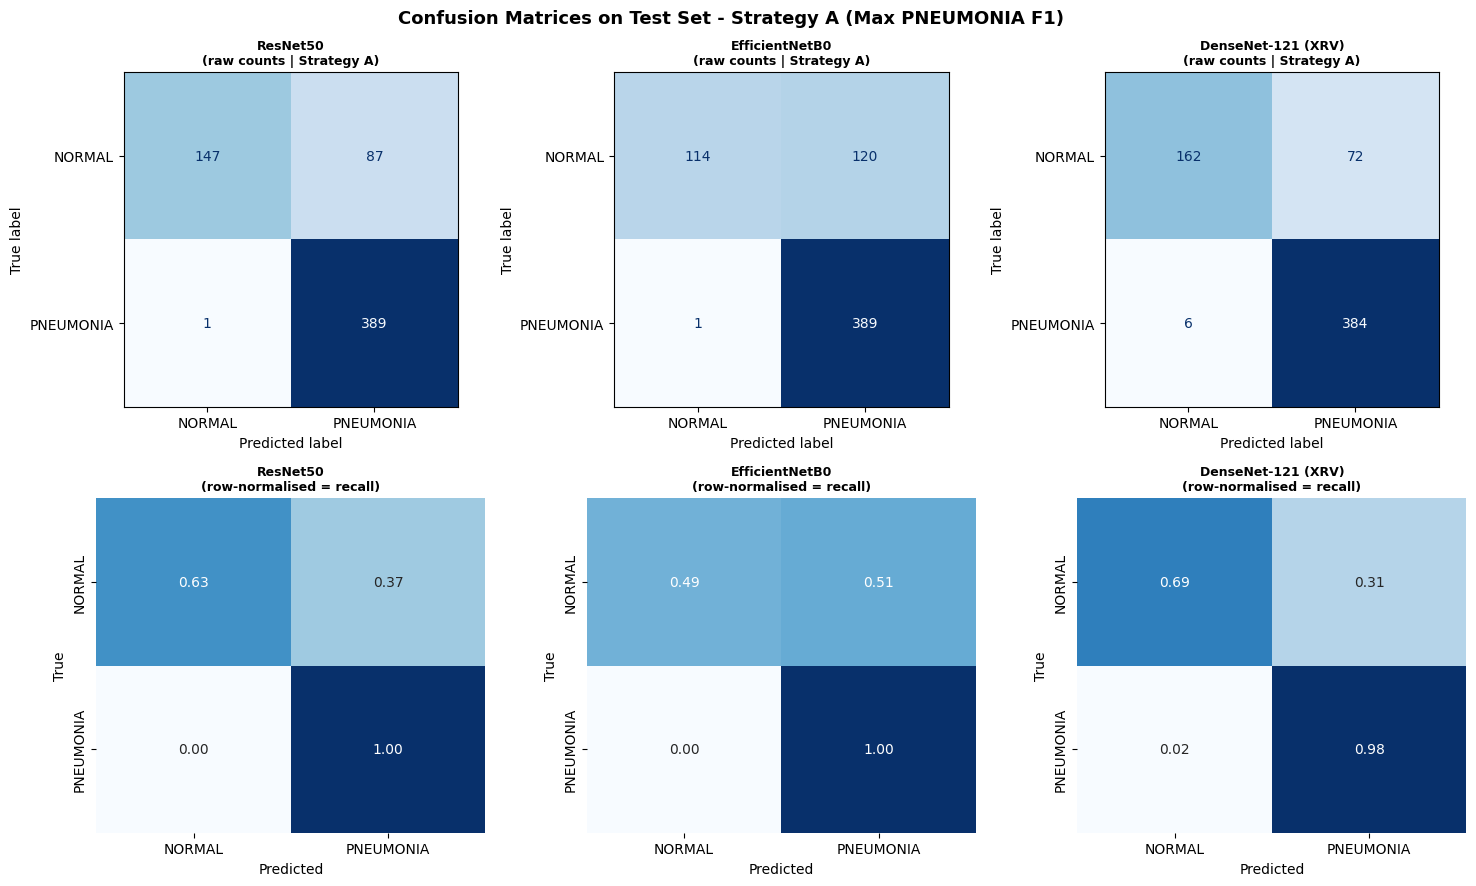

In [23]:
# Show confusion matrices for Strategy A (max F1)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, (name, res) in enumerate(test_results.items()):
    cm      = confusion_matrix(res['labels'], res['preds_f1'])
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
    disp.plot(ax=axes[0, col], colorbar=False, cmap='Blues')
    axes[0, col].set_title(f'{name}\n(raw counts | Strategy A)', fontweight='bold', fontsize=9)

    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                ax=axes[1, col], cbar=False)
    axes[1, col].set_xlabel('Predicted'); axes[1, col].set_ylabel('True')
    axes[1, col].set_title(f'{name}\n(row-normalised = recall)', fontweight='bold', fontsize=9)

plt.suptitle('Confusion Matrices on Test Set - Strategy A (Max PNEUMONIA F1)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


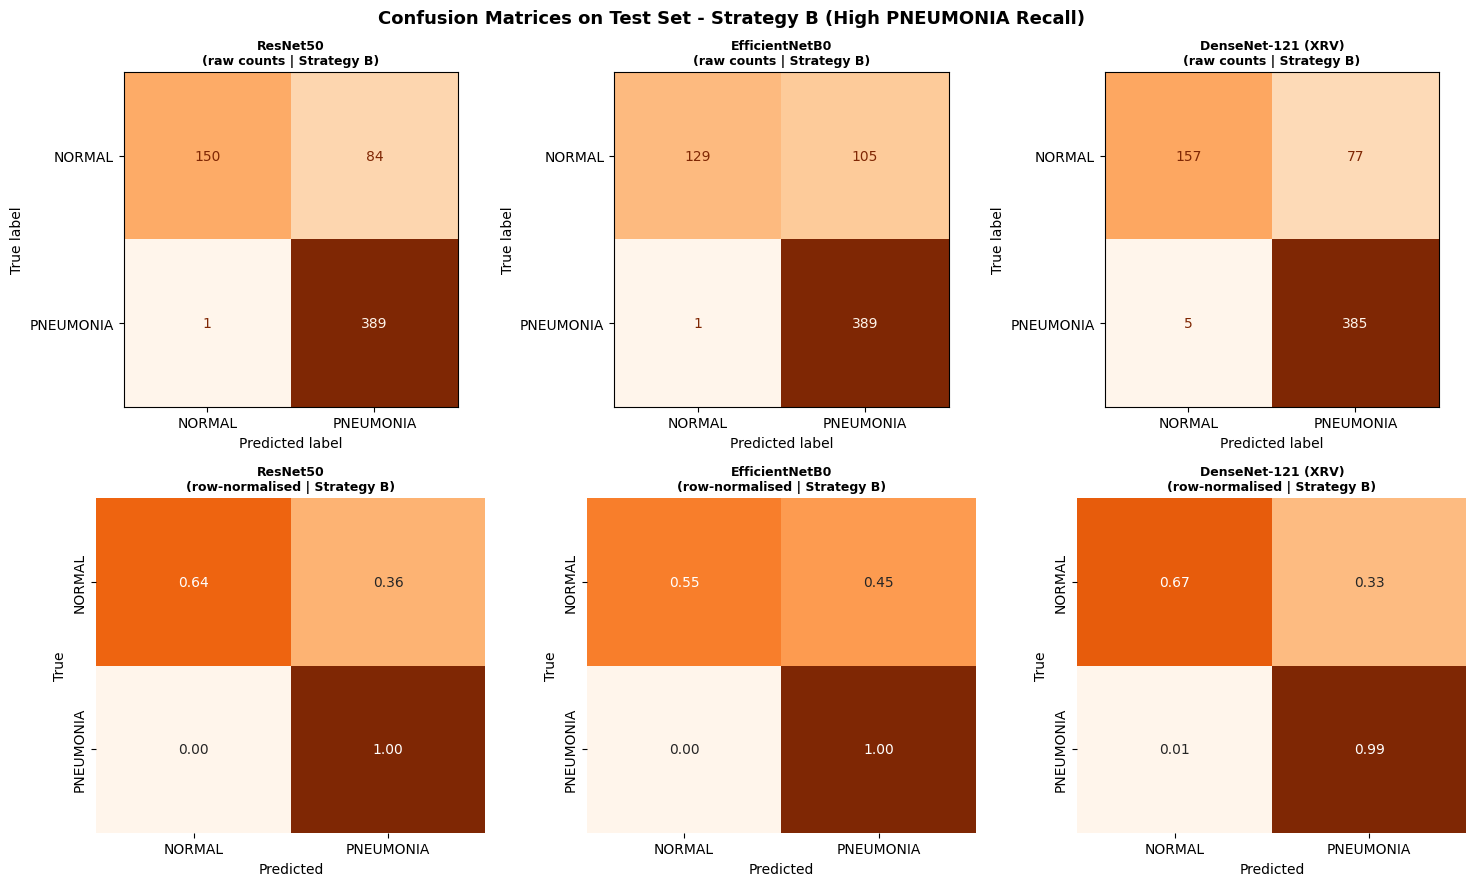


Interpretation: Strategy B lowers the threshold to catch more PNEUMONIA-labeled images (fewer false negatives),
at the cost of more false positives. The trade-off between FN and FP is important:
  - False Negatives (PNEUMONIA → NORMAL): PNEUMONIA-labeled images predicted as NORMAL - the primary risk in this screening-style task.
  - False Positives (NORMAL → PNEUMONIA): NORMAL-labeled images incorrectly flagged as PNEUMONIA - a secondary concern.



In [24]:
# Show confusion matrices for Strategy B (high recall)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, (name, res) in enumerate(test_results.items()):
    cm      = confusion_matrix(res['labels'], res['preds_recall'])
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
    disp.plot(ax=axes[0, col], colorbar=False, cmap='Oranges')
    axes[0, col].set_title(f'{name}\n(raw counts | Strategy B)', fontweight='bold', fontsize=9)

    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Oranges',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                ax=axes[1, col], cbar=False)
    axes[1, col].set_xlabel('Predicted'); axes[1, col].set_ylabel('True')
    axes[1, col].set_title(f'{name}\n(row-normalised | Strategy B)', fontweight='bold', fontsize=9)

plt.suptitle('Confusion Matrices on Test Set - Strategy B (High PNEUMONIA Recall)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print("""
Interpretation: Strategy B lowers the threshold to catch more PNEUMONIA-labeled images (fewer false negatives),
at the cost of more false positives. The trade-off between FN and FP is important:
  - False Negatives (PNEUMONIA → NORMAL): PNEUMONIA-labeled images predicted as NORMAL - the primary risk in this screening-style task.
  - False Positives (NORMAL → PNEUMONIA): NORMAL-labeled images incorrectly flagged as PNEUMONIA - a secondary concern.
""")


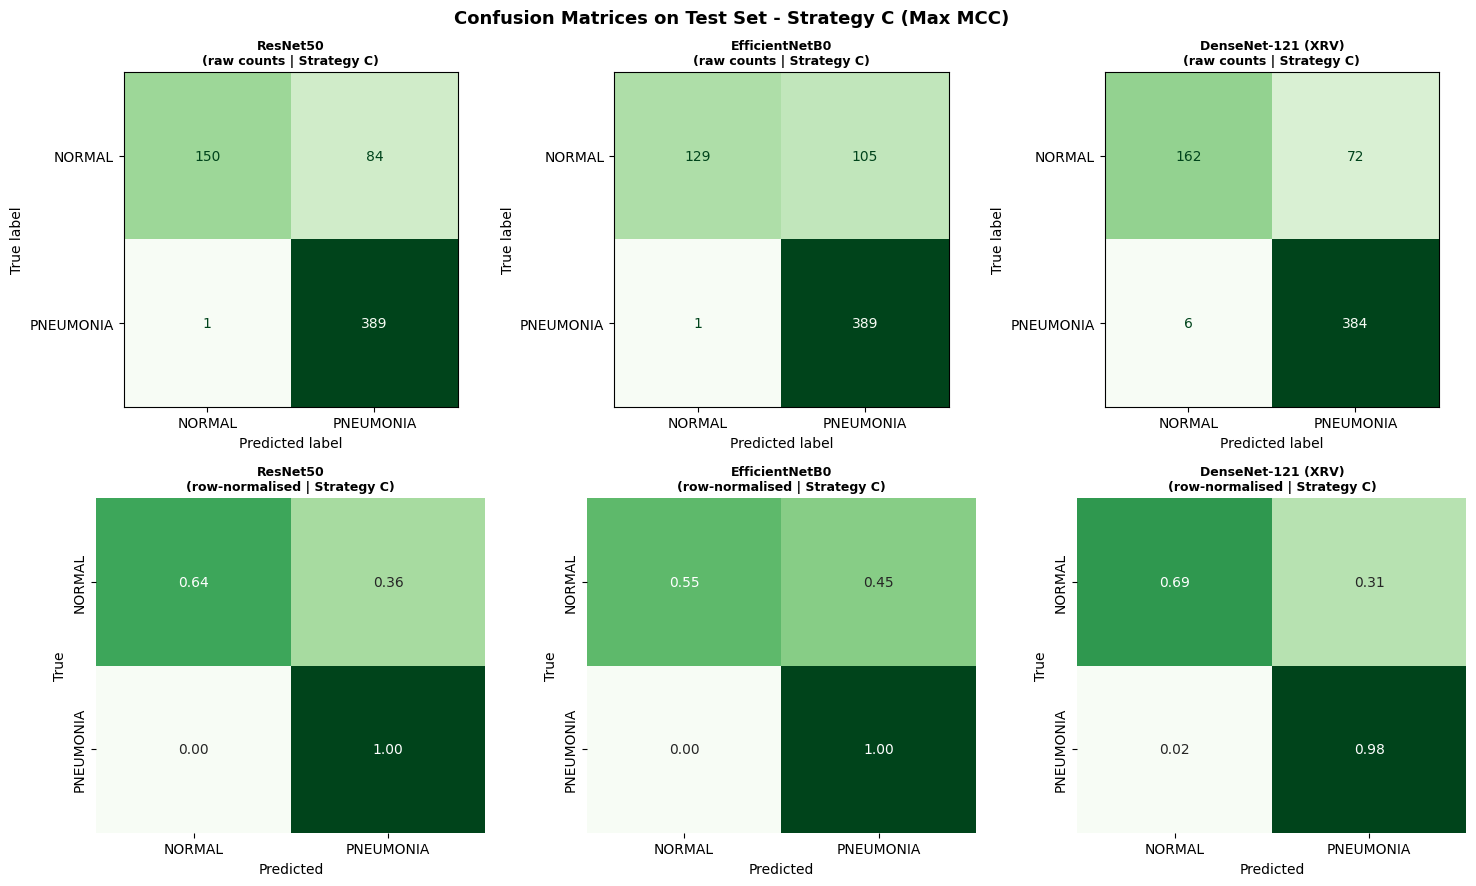

In [25]:
# Show confusion matrices for Strategy C (max MCC)
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for col, (name, res) in enumerate(test_results.items()):
    cm      = confusion_matrix(res['labels'], res['preds_mcc'])
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    disp = ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES)
    disp.plot(ax=axes[0, col], colorbar=False, cmap='Greens')
    axes[0, col].set_title(f'{name}\n(raw counts | Strategy C)', fontweight='bold', fontsize=9)

    sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Greens',
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
                ax=axes[1, col], cbar=False)
    axes[1, col].set_xlabel('Predicted'); axes[1, col].set_ylabel('True')
    axes[1, col].set_title(f'{name}\n(row-normalised | Strategy C)', fontweight='bold', fontsize=9)

plt.suptitle('Confusion Matrices on Test Set - Strategy C (Max MCC)', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()


**Interpreting the test-set results:**

The confusion matrices show a consistent pattern. ResNet50 and EfficientNetB0 achieve high PNEUMONIA recall, but at the cost of many false positives - NORMAL-labeled images are frequently predicted as PNEUMONIA. This suggests that ImageNet-pretrained features, even after end-to-end fine-tuning, do not produce a well-calibrated decision boundary for chest X-ray images.

**DenseNet-121 XRV with Strategy C** gives the best overall balance: the highest MCC, the fewest false positives, and the best NORMAL recall among the three main models, while keeping PNEUMONIA recall high. Starting from chest X-ray pretrained features appears to give the model a more reliable starting point for separating the two classes.

**Strategy B** lowers the threshold to catch more PNEUMONIA-labeled images, reducing false negatives at the cost of more false positives. This can be an appropriate trade-off when screening sensitivity is the main priority. **Strategy C** gives the most balanced result and is the recommended general-purpose operating point.

There is no universally correct threshold. The best choice depends on the clinical setting and how false negatives and false positives are weighted against each other.


### 7.2 ROC and Precision-Recall Curves

ROC and precision-recall curves show how each model performs across **all possible thresholds**, not just the ones selected in Section 6. This gives a threshold-independent view of discriminative ability.

**AUROC** measures how well the model ranks PNEUMONIA cases above NORMAL ones. A high AUROC means the model assigns higher probabilities to positive cases on average. It does not guarantee that false positives are low at any particular threshold - a model can have high AUROC and still produce many false positives at the operating threshold chosen for deployment.

**AUPRC** summarizes precision-recall behavior for the positive (PNEUMONIA) class. Because PNEUMONIA is the majority class in both the training/validation pool (~74.3%) and the official test set (62.5%), the baseline AUPRC for a random classifier is already elevated. A high AUPRC alone does not mean NORMAL recall is good or that false positives are low.

Both curves are most useful when read alongside the threshold-specific metrics from Section 7.1 - MCC, per-class recall, false positives, and false negatives. The curves here provide the ranking picture; the confusion matrices provide the operating-point picture.


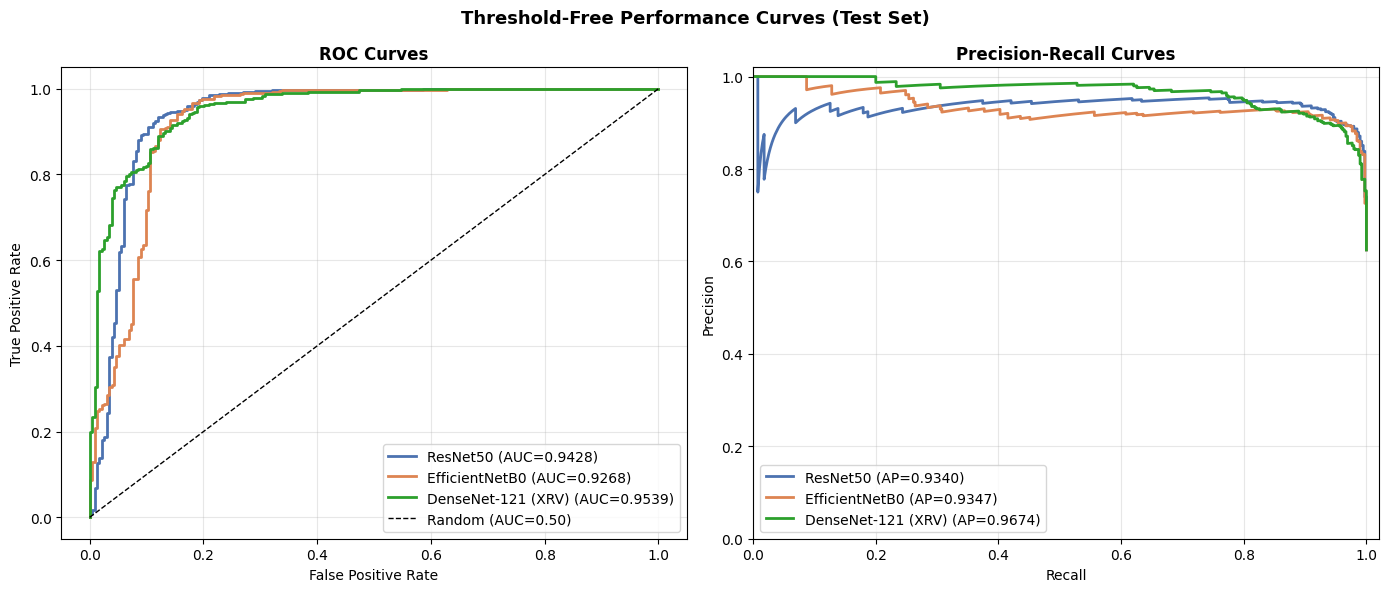


Interpretation: AUPRC evaluates precision-recall behavior for the clinically important PNEUMONIA class.
PNEUMONIA is the majority class in both the train/validation split (~74.3%) and the official test set
(390/624 = 62.5%), but the prevalence is lower in the test set. Because AUPRC focuses on the positive
class, it should not be interpreted alone; a high AUPRC does not guarantee good NORMAL recall or
low false positives.

AUROC measures threshold-free ranking performance. It is useful, but it can still look strong even when
a chosen decision threshold produces many false positives. Therefore, AUROC and AUPRC are interpreted
together with MCC, NORMAL recall, false positives, and false negatives.



In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = ['#4C72B0', '#DD8452', '#2CA02C']

for (name, res), color in zip(test_results.items(), colors):
    fpr, tpr, _ = roc_curve(res['labels'], res['probs'])
    roc_auc = auc(fpr, tpr)
    axes[0].plot(fpr, tpr, color=color, lw=2, label=f'{name} (AUC={roc_auc:.4f})')

    prec, rec, _ = precision_recall_curve(res['labels'], res['probs'])
    ap = average_precision_score(res['labels'], res['probs'])
    axes[1].plot(rec, prec, color=color, lw=2, label=f'{name} (AP={ap:.4f})')

axes[0].plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC=0.50)')
axes[0].set_xlabel('False Positive Rate'); axes[0].set_ylabel('True Positive Rate')
axes[0].set_title('ROC Curves', fontweight='bold'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].set_xlabel('Recall'); axes[1].set_ylabel('Precision')
axes[1].set_title('Precision-Recall Curves', fontweight='bold'); axes[1].legend()
axes[1].grid(True, alpha=0.3); axes[1].set_xlim(0, 1.02); axes[1].set_ylim(0, 1.02)

plt.suptitle('Threshold-Free Performance Curves (Test Set)', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

print("""
Interpretation: AUPRC evaluates precision-recall behavior for the clinically important PNEUMONIA class.
PNEUMONIA is the majority class in both the train/validation split (~74.3%) and the official test set
(390/624 = 62.5%), but the prevalence is lower in the test set. Because AUPRC focuses on the positive
class, it should not be interpreted alone; a high AUPRC does not guarantee good NORMAL recall or
low false positives.

AUROC measures threshold-free ranking performance. It is useful, but it can still look strong even when
a chosen decision threshold produces many false positives. Therefore, AUROC and AUPRC are interpreted
together with MCC, NORMAL recall, false positives, and false negatives.
""")


### 7.3 False Negative / False Positive Image Analysis

Aggregate metrics summarize overall behavior but can hide specific failure modes. Looking at the actual misclassified images helps identify whether errors cluster in visually unusual cases, borderline images, or specific artifact patterns.

The examples shown are the **most confidently wrong predictions** - images where the model assigned a high probability to the wrong class. These are worth examining because they represent the clearest failures, not just marginal ones.

**False negatives** (PNEUMONIA-labeled images predicted as NORMAL) are the most critical screening error in this task because the model fails to flag an image from the positive class. **False positives** (NORMAL-labeled images predicted as PNEUMONIA) reduce specificity and may lead to possible unnecessary follow-up. This is why both error types are inspected instead of relying only on accuracy.

Important caveat: visual inspection can suggest hypotheses about failure modes but cannot explain them definitively. Some errors may come from genuinely ambiguous images, preprocessing artifacts, dataset noise, or shortcut features learned from image properties unrelated to the pathology. Any specific radiological interpretation of these cases would require review by a trained radiologist.



[ResNet50] threshold=0.443
  False Negatives (PNEUMONIA→NORMAL): 1 | False Positives (NORMAL→PNEUMONIA): 87


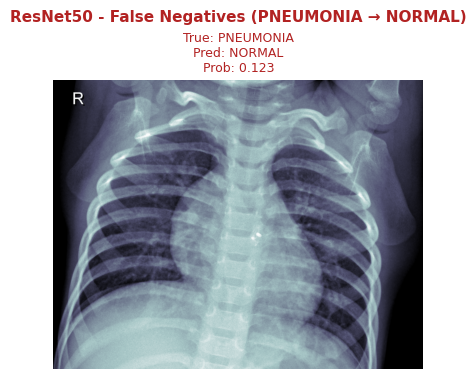

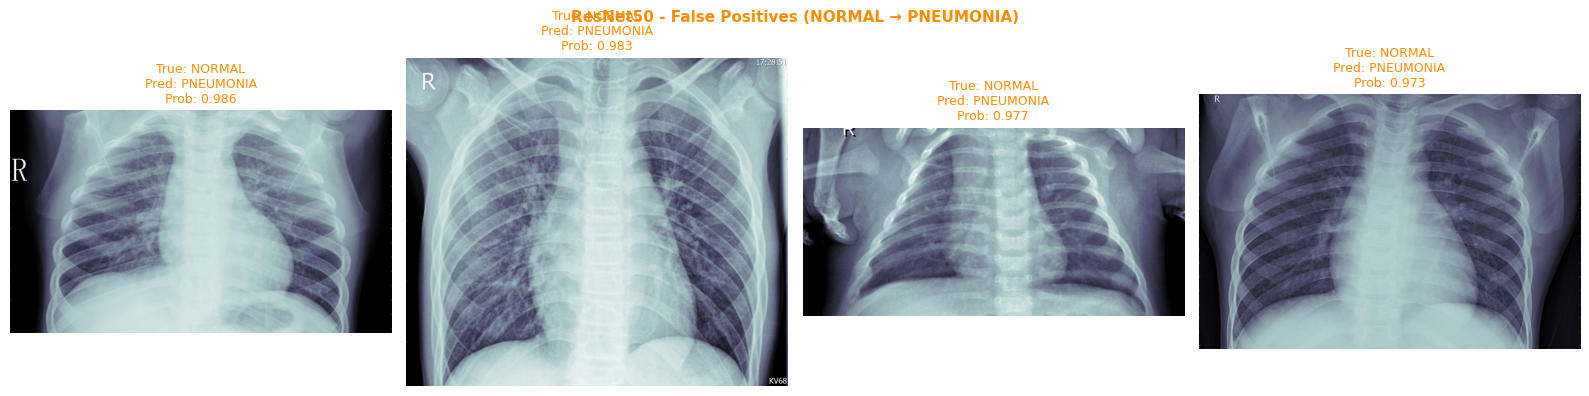


[EfficientNetB0] threshold=0.169
  False Negatives (PNEUMONIA→NORMAL): 1 | False Positives (NORMAL→PNEUMONIA): 120


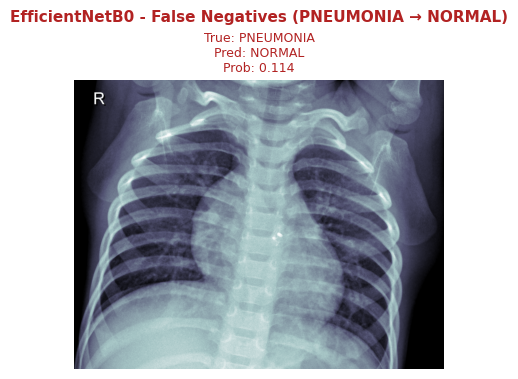

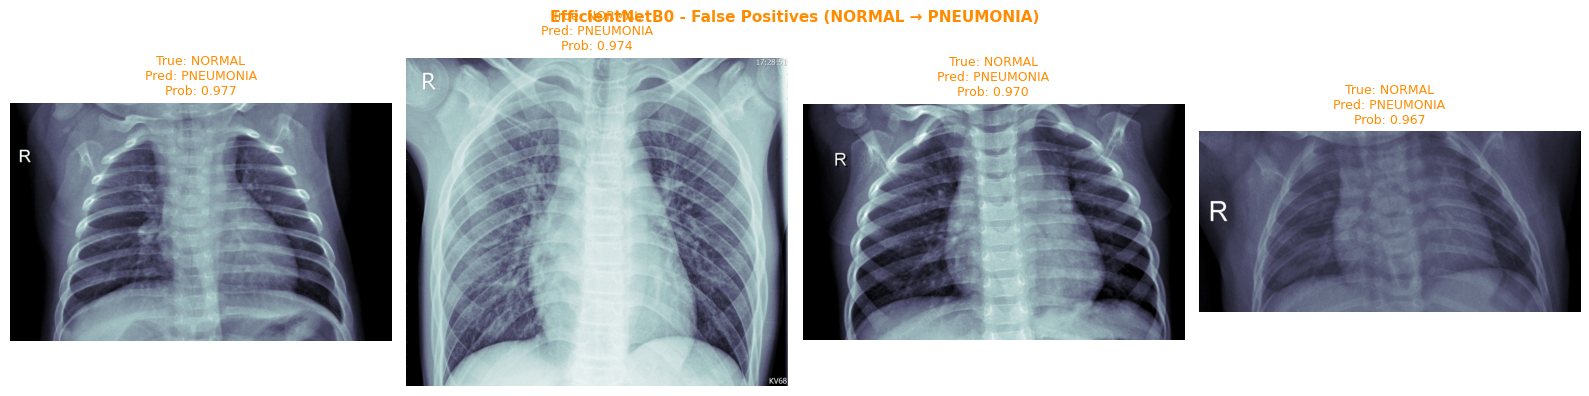


[DenseNet-121 (XRV)] threshold=0.367
  False Negatives (PNEUMONIA→NORMAL): 6 | False Positives (NORMAL→PNEUMONIA): 72


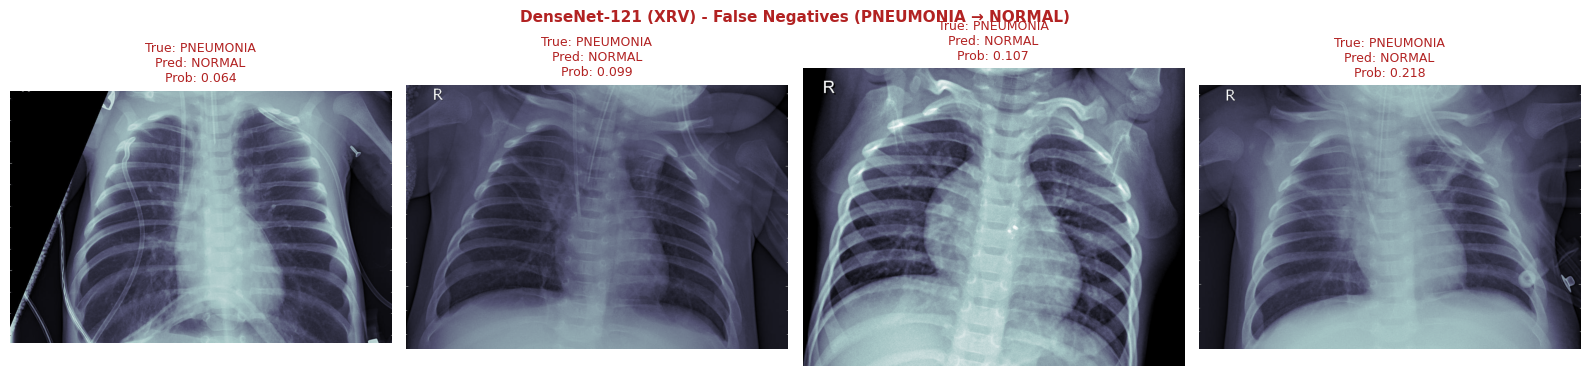

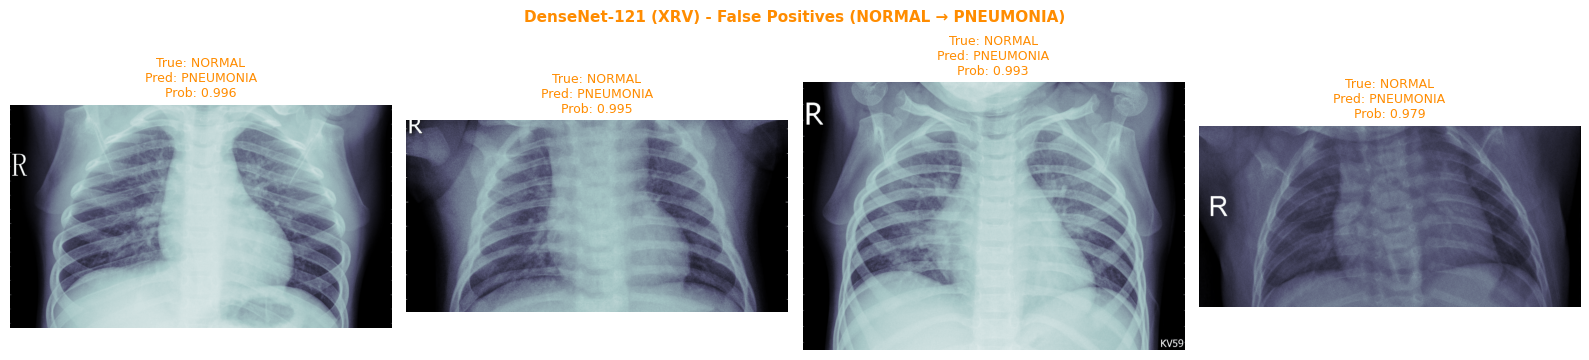

In [27]:
def show_errors(model_name, probs, preds, true_labels, image_paths, class_names, thr, n=4):
    FN_idx = np.where((true_labels == 1) & (preds == 0))[0]
    FP_idx = np.where((true_labels == 0) & (preds == 1))[0]

    print(f"\n[{model_name}] threshold={thr:.3f}")
    print(f"  False Negatives (PNEUMONIA→NORMAL): {len(FN_idx)} | "
          f"False Positives (NORMAL→PNEUMONIA): {len(FP_idx)}")

    for error_type, idx_arr, title_color in [
        ('False Negatives (PNEUMONIA → NORMAL)', FN_idx, 'firebrick'),
        ('False Positives (NORMAL → PNEUMONIA)',  FP_idx, 'darkorange')
    ]:
        n_show = min(n, len(idx_arr))
        if n_show == 0:
            print(f"  No {error_type.split('(')[0].strip()} to display.")
            continue
        sorted_by_conf = idx_arr[np.argsort(np.abs(probs[idx_arr] - thr))[::-1]]
        show_idx = sorted_by_conf[:n_show]

        fig, axes = plt.subplots(1, n_show, figsize=(4 * n_show, 4))
        if n_show == 1:
            axes = [axes]
        for ax, i in zip(axes, show_idx):
            img = Image.open(image_paths[i]).convert('L')
            ax.imshow(img, cmap='bone')
            ax.set_title(
                f'True: {class_names[true_labels[i]]}\nPred: {class_names[preds[i]]}\nProb: {probs[i]:.3f}',
                fontsize=9, color=title_color
            )
            ax.axis('off')
        plt.suptitle(f'{model_name} - {error_type}', fontsize=11, fontweight='bold', color=title_color)
        plt.tight_layout(); plt.show()

# Use Strategy A predictions for error visualisation
for name, res in test_results.items():
    show_errors(name, res['probs'], res['preds_f1'], res['labels'], test_paths, CLASS_NAMES, res['thr_f1'])


---
## 8. Ensemble Model

Model ensembles can reduce errors when individual models fail on different images. ResNet50 and DenseNet-121 XRV come from different starting points - ImageNet pretraining versus chest X-ray pretraining - so they may disagree on different subsets of the test set.

The ensemble here uses simple **equal-weight probability averaging**:

```
ensemble_prob = 0.5 × ResNet50_prob + 0.5 × DenseNet-121 XRV_prob
```

The ensemble threshold is selected on the averaged validation probabilities using the same three strategies as the individual models, then applied once to the test set.

Simple equal-weight averaging does not always produce the best thresholded classifier even when it improves AUROC or AUPRC. The two models may have different probability scales and calibrations, so their average may not align well with either model's validation distribution. If the ensemble does not outperform DenseNet-121 XRV Strategy C on MCC and NORMAL recall, this will be stated directly.


In [28]:
# Ensemble probabilities
# Both ResNet and DenseNet share the same test images; labels should be identical
assert np.array_equal(resnet_test_labels, densenet_test_labels), "Label mismatch between loaders!"

ensemble_test_probs = 0.5 * resnet_test_probs + 0.5 * densenet_test_probs
ensemble_labels     = resnet_test_labels

# Tune ensemble thresholds on validation set
ensemble_val_probs  = 0.5 * resnet_val_probs + 0.5 * densenet_val_probs
ensemble_val_labels = resnet_val_labels

ensemble_thr_f1, ensemble_thr_recall, ensemble_thr_mcc = select_thresholds(
    ensemble_val_probs, ensemble_val_labels, 'Ensemble (ResNet50 + DenseNet-121 XRV)'
)

# Apply to test set
ensemble_preds_f1     = (ensemble_test_probs >= ensemble_thr_f1).astype(int)
ensemble_preds_recall = (ensemble_test_probs >= ensemble_thr_recall).astype(int)
ensemble_preds_mcc    = (ensemble_test_probs >= ensemble_thr_mcc).astype(int)

print("\nEnsemble - Strategy A (Max PNEUMONIA F1):")
print(classification_report(ensemble_labels, ensemble_preds_f1, target_names=CLASS_NAMES, digits=4))
m_ens_a = full_metrics(ensemble_labels, ensemble_preds_f1, ensemble_test_probs, CLASS_NAMES)
print(f"  AUROC={m_ens_a['AUROC']}  AUPRC={m_ens_a['AUPRC']}  MCC={m_ens_a['MCC']}  "
      f"FN={m_ens_a['False Negatives']}  FP={m_ens_a['False Positives']}")

print("\nEnsemble - Strategy B (High Recall):")
print(classification_report(ensemble_labels, ensemble_preds_recall, target_names=CLASS_NAMES, digits=4))
m_ens_b = full_metrics(ensemble_labels, ensemble_preds_recall, ensemble_test_probs, CLASS_NAMES)
print(f"  AUROC={m_ens_b['AUROC']}  AUPRC={m_ens_b['AUPRC']}  MCC={m_ens_b['MCC']}  "
      f"FN={m_ens_b['False Negatives']}  FP={m_ens_b['False Positives']}")

print("\nEnsemble - Strategy C (Max MCC):")
print(classification_report(ensemble_labels, ensemble_preds_mcc, target_names=CLASS_NAMES, digits=4))
m_ens_c = full_metrics(ensemble_labels, ensemble_preds_mcc, ensemble_test_probs, CLASS_NAMES)
print(f"  AUROC={m_ens_c['AUROC']}  AUPRC={m_ens_c['AUPRC']}  MCC={m_ens_c['MCC']}  "
      f"FN={m_ens_c['False Negatives']}  FP={m_ens_c['False Positives']}")



Ensemble (ResNet50 + DenseNet-121 XRV) threshold selection (val set):
  Strategy A (max PNEUMONIA F1):   thr=0.285 | F1=0.9904 | Precision=0.986 | Recall=0.995
  Strategy B (recall>=0.97):  thr=0.303 | MCC=0.9622 | PNEUMONIA recall≈0.994
  Strategy C (max MCC):            thr=0.303 | val MCC=0.9622

Ensemble - Strategy A (Max PNEUMONIA F1):
              precision    recall  f1-score   support

      NORMAL     0.9926    0.5769    0.7297       234
   PNEUMONIA     0.7971    0.9974    0.8861       390

    accuracy                         0.8397       624
   macro avg     0.8949    0.7872    0.8079       624
weighted avg     0.8704    0.8397    0.8275       624

  AUROC=0.9644  AUPRC=0.9643  MCC=0.6735  FN=1  FP=99

Ensemble - Strategy B (High Recall):
              precision    recall  f1-score   support

      NORMAL     0.9928    0.5897    0.7399       234
   PNEUMONIA     0.8021    0.9974    0.8891       390

    accuracy                         0.8446       624
   macro avg     0.

**Ensemble result:** The ensemble achieves the highest AUROC and AUPRC among all approaches, which shows that ResNet50 and DenseNet-121 XRV capture partially different information about the images. However, this ranking improvement did not carry over to thresholded classification: the ensemble produced more false positives and a lower MCC than DenseNet-121 XRV under Strategy C. This is a known limitation of uncalibrated equal-weight averaging - the averaged probabilities can have a different scale and distribution than either individual model, so a threshold selected on validation probabilities may not be at the right operating point.

**Equal-weight averaging improved ranking but not the final thresholded classifier.** DenseNet-121 XRV with Strategy C remains the recommended model. A calibrated or weighted ensemble could potentially improve thresholded performance, but that is left for future work.


---
## 9. Test-Time Augmentation (TTA)

Test-time augmentation runs inference on multiple slightly different versions of each test image - horizontal flip, small rotation, mild brightness change - and averages the predictions. The idea is that the predicted class should not depend on small irrelevant variations, so averaging over them produces a smoother, lower-variance probability estimate.

TTA is demonstrated here for **ResNet50** as a representative example, using five augmented views.

One important limitation: the decision thresholds for ResNet50 were selected on **non-TTA validation probabilities**. If TTA changes the distribution of predicted probabilities, the fixed threshold may not be at the right operating point. A properly set-up TTA system would re-select thresholds on TTA-transformed validation predictions. The comparison below should therefore be read as a ranking and stability experiment, not as an optimized deployment comparison.


In [29]:
@torch.no_grad()
def tta_predict(model, dataset, device, model_type='softmax', n_aug=5, batch_size=32):
    """
    Test-Time Augmentation for ResNet-style (softmax) models.
    Returns averaged probabilities over n_aug augmented versions.
    """
    tta_transforms = [
        transforms.Compose([
            transforms.Resize(256), transforms.CenterCrop(224),
            transforms.Grayscale(3), transforms.ToTensor(),
            transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]),
        transforms.Compose([
            transforms.Resize(256), transforms.CenterCrop(224),
            transforms.Grayscale(3), transforms.RandomHorizontalFlip(p=1.0),
            transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]),
        transforms.Compose([
            transforms.Resize(256), transforms.CenterCrop(224),
            transforms.Grayscale(3), transforms.RandomRotation(10),
            transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]),
        transforms.Compose([
            transforms.Resize(256), transforms.CenterCrop(224),
            transforms.Grayscale(3), transforms.ColorJitter(brightness=0.15),
            transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]),
        transforms.Compose([
            transforms.Resize(256), transforms.CenterCrop(224),
            transforms.Grayscale(3),
            transforms.RandomHorizontalFlip(p=1.0),
            transforms.RandomRotation(5),
            transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]),
    ][:n_aug]

    samples    = dataset.samples
    all_labels = np.array([s[1] for s in samples])
    all_probs  = np.zeros(len(samples), dtype=np.float32)

    for aug_tf in tta_transforms:
        aug_dataset = datasets.ImageFolder(TEST_DIR, transform=aug_tf)
        aug_loader  = DataLoader(aug_dataset, batch_size=batch_size, shuffle=False,
                                 num_workers=4, pin_memory=True)
        model.eval()
        aug_probs = []
        for images, _ in aug_loader:
            images = images.to(device)
            if model_type == 'softmax':
                probs = torch.softmax(model(images), dim=1)[:, 1].cpu().numpy()
            else:
                probs = torch.sigmoid(model(images)).cpu().numpy()
            aug_probs.extend(probs)
        all_probs += np.array(aug_probs)

    all_probs /= len(tta_transforms)
    return all_probs, all_labels


print("Running TTA for ResNet50 (5 augmentations)...")
tta_probs, tta_labels = tta_predict(resnet_model, test_dataset, DEVICE, model_type='softmax', n_aug=5)

# Apply the same threshold that was selected on non-TTA validation probs.
# Note: ideally TTA threshold would be re-selected on TTA-transformed val probs,
# but since we did not collect TTA val probs, we reuse the existing Strategy A threshold
# as a direct apples-to-apples comparison of TTA vs no-TTA inference.
tta_preds    = (tta_probs >= resnet_thr_f1).astype(int)
resnet_preds_f1_ref = (resnet_test_probs >= resnet_thr_f1).astype(int)

m_no_tta = full_metrics(resnet_test_labels, resnet_preds_f1_ref, resnet_test_probs, CLASS_NAMES)
m_tta    = full_metrics(tta_labels, tta_preds, tta_probs, CLASS_NAMES)

print("\nResNet50 - TTA vs No-TTA comparison (Strategy A threshold):")
comp_df = pd.DataFrame({'No TTA': m_no_tta, 'With TTA': m_tta}).T
print(comp_df[['Accuracy', 'AUROC', 'AUPRC', 'MCC', 'Recall-PNEUMONIA', 'False Negatives', 'False Positives']].to_string())

print("""
Interpretation: TTA improved threshold-free ranking metrics such as AUROC/AUPRC by averaging
over slightly different views of each image, which smooths the probability surface. However,
it did not substantially improve thresholded metrics (MCC, FN, FP) under the fixed
Strategy A threshold, because the threshold was selected on non-TTA validation probabilities.
TTA should therefore be interpreted as a stability/ranking improvement rather than a major
classification improvement. To fully exploit TTA, the threshold should be re-selected on
TTA-transformed validation probabilities.
""")


Running TTA for ResNet50 (5 augmentations)...

ResNet50 - TTA vs No-TTA comparison (Strategy A threshold):
          Accuracy   AUROC   AUPRC     MCC  Recall-PNEUMONIA  False Negatives  False Positives
No TTA       85.90  0.9428  0.9340  0.7121            0.9974              1.0             87.0
With TTA     85.74  0.9593  0.9518  0.7089            0.9974              1.0             88.0

Interpretation: TTA improved threshold-free ranking metrics such as AUROC/AUPRC by averaging
over slightly different views of each image, which smooths the probability surface. However,
it did not substantially improve thresholded metrics (MCC, FN, FP) under the fixed
Strategy A threshold, because the threshold was selected on non-TTA validation probabilities.
TTA should therefore be interpreted as a stability/ranking improvement rather than a major
classification improvement. To fully exploit TTA, the threshold should be re-selected on
TTA-transformed validation probabilities.



**TTA result:** TTA improved AUROC and AUPRC for ResNet50, which is consistent with the idea that averaging over small perturbations smooths the probability surface. Thresholded metrics (MCC, FP, FN) did not substantially improve under the fixed Strategy A threshold - the threshold was not tuned for TTA probabilities, so this is expected.

TTA is a useful tool for improving ranking quality and prediction stability. To get the most from it in a real deployment, thresholds should be re-selected on TTA-transformed validation predictions rather than reused from standard inference.


---
## 10. Final Comparison Table

This table collects all models under all three threshold strategies - plus the ensemble and TTA results - in one place for direct comparison.

The most informative columns for choosing a deployed model are **MCC** (overall balance), **Recall-NORMAL** (false-positive control), **False Negatives** (PNEUMONIA-labeled images predicted as NORMAL), and **False Positives** (NORMAL-labeled images predicted as PNEUMONIA). AUROC and AUPRC measure ranking quality across all thresholds and should not be the primary criterion for selecting a classifier at a specific operating point.


In [30]:
from sklearn.metrics import precision_recall_fscore_support

def make_row(name, strategy, thr, probs, labels, preds):
    m = full_metrics(labels, preds, probs, CLASS_NAMES)
    return {
        'Model':               name,
        'Strategy':            strategy,
        'Threshold':           round(thr, 3),
        'Accuracy (%)':        m['Accuracy'],
        'AUROC':               m['AUROC'],
        'AUPRC':               m['AUPRC'],
        'MCC':                 m['MCC'],
        'Recall-PNEUMONIA':    m['Recall-PNEUMONIA'],
        'Precision-PNEUMONIA': m['Precision-PNEUMONIA'],
        'F1-PNEUMONIA':        m['F1-PNEUMONIA'],
        'Recall-NORMAL':       m['Recall-NORMAL'],
        'False Negatives':     m['False Negatives'],
        'False Positives':     m['False Positives'],
    }

comparison_rows = []
for name, res in test_results.items():
    comparison_rows.append(make_row(name, 'A (Max PNEUMONIA F1)', res['thr_f1'],     res['probs'], res['labels'], res['preds_f1']))
    comparison_rows.append(make_row(name, 'B (Hi-Recall)',        res['thr_recall'], res['probs'], res['labels'], res['preds_recall']))
    comparison_rows.append(make_row(name, 'C (Max MCC)',          res['thr_mcc'],    res['probs'], res['labels'], res['preds_mcc']))

# Ensemble
comparison_rows.append(make_row('Ensemble (R50+DN)', 'A (Max PNEUMONIA F1)', ensemble_thr_f1,     ensemble_test_probs, ensemble_labels, ensemble_preds_f1))
comparison_rows.append(make_row('Ensemble (R50+DN)', 'B (Hi-Recall)',        ensemble_thr_recall, ensemble_test_probs, ensemble_labels, ensemble_preds_recall))
comparison_rows.append(make_row('Ensemble (R50+DN)', 'C (Max MCC)',          ensemble_thr_mcc,    ensemble_test_probs, ensemble_labels, ensemble_preds_mcc))

# TTA ResNet50 - reuse Strategy A threshold (no TTA val probs available)
comparison_rows.append(make_row('ResNet50 + TTA', 'A (Max PNEUMONIA F1)', resnet_thr_f1, tta_probs, tta_labels, tta_preds))

df_comparison = pd.DataFrame(comparison_rows).set_index(['Model', 'Strategy'])
print("\n=== FINAL MODEL COMPARISON TABLE ===")
print(df_comparison.to_string())



=== FINAL MODEL COMPARISON TABLE ===
                                         Threshold  Accuracy (%)   AUROC   AUPRC     MCC  Recall-PNEUMONIA  Precision-PNEUMONIA  F1-PNEUMONIA  Recall-NORMAL  False Negatives  False Positives
Model              Strategy                                                                                                                                                                   
ResNet50           A (Max PNEUMONIA F1)      0.443         85.90  0.9428  0.9340  0.7121            0.9974               0.8172        0.8984         0.6282                1               87
                   B (Hi-Recall)             0.511         86.38  0.9428  0.9340  0.7217            0.9974               0.8224        0.9015         0.6410                1               84
                   C (Max MCC)               0.511         86.38  0.9428  0.9340  0.7217            0.9974               0.8224        0.9015         0.6410                1               84
Efficie

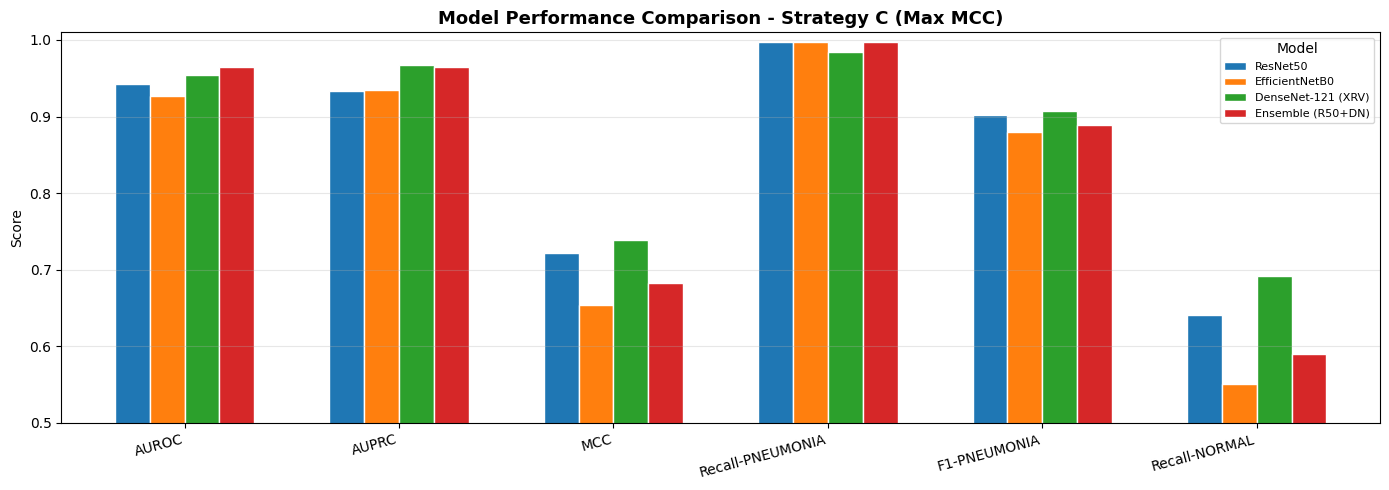

In [31]:
# Bar chart: key metrics across models (Strategy C)
df_plot = df_comparison.loc[
    df_comparison.index.get_level_values('Strategy') == 'C (Max MCC)',
    ['AUROC', 'AUPRC', 'MCC', 'Recall-PNEUMONIA', 'F1-PNEUMONIA', 'Recall-NORMAL']
].copy()

df_plot.index = df_plot.index.get_level_values('Model')

ax = df_plot.T.plot(kind='bar', figsize=(14, 5), edgecolor='white', width=0.65)
ax.set_title('Model Performance Comparison - Strategy C (Max MCC)', fontsize=13, fontweight='bold')
ax.set_ylabel('Score')
ax.set_xticklabels(df_plot.columns.tolist(), rotation=15, ha='right')
ax.legend(title='Model', fontsize=8)
ax.set_ylim(0.5, 1.01)
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---
## 11. GradCAM - Where Does the Model Look?

GradCAM uses the gradients flowing into a target convolutional layer to produce a heatmap that highlights which image regions most influenced the prediction. For a chest X-ray classifier, this is a useful sanity check: is the model attending to the lung fields, or to irrelevant features like image borders, corner labels, or scanner markings?

Target layers used: `resnet_model.layer4[-1]` (ResNet50), `effnet_model.features[-1]` (EfficientNetB0), `densenet_model.backbone.features.denseblock4` (DenseNet-121 XRV).

**What to look for:**
- Attention inside the **lung fields** is a positive sign - the model may be responding to clinically relevant anatomy or density patterns.
- Attention on **corners, borders, image labels, or regions outside the lungs** suggests shortcut learning. This is a genuine risk with datasets from a single source, where all NORMAL and PNEUMONIA images may share systematic formatting differences.

This is a **qualitative sanity check, not clinical validation**. GradCAM heatmaps show which regions influenced the current model's output - they do not tell us whether those regions contain real diagnostic evidence or are a spurious correlation. Any radiological interpretation of specific heatmaps would need a trained radiologist.


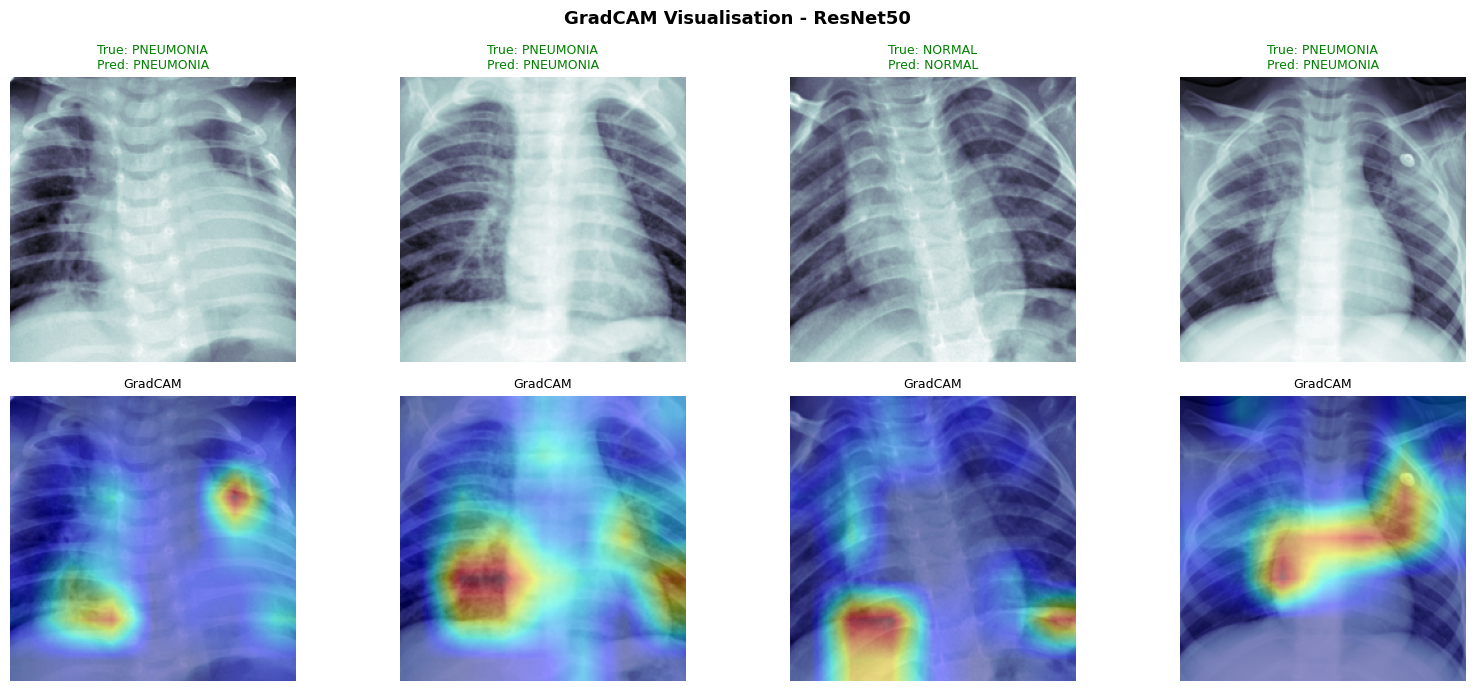

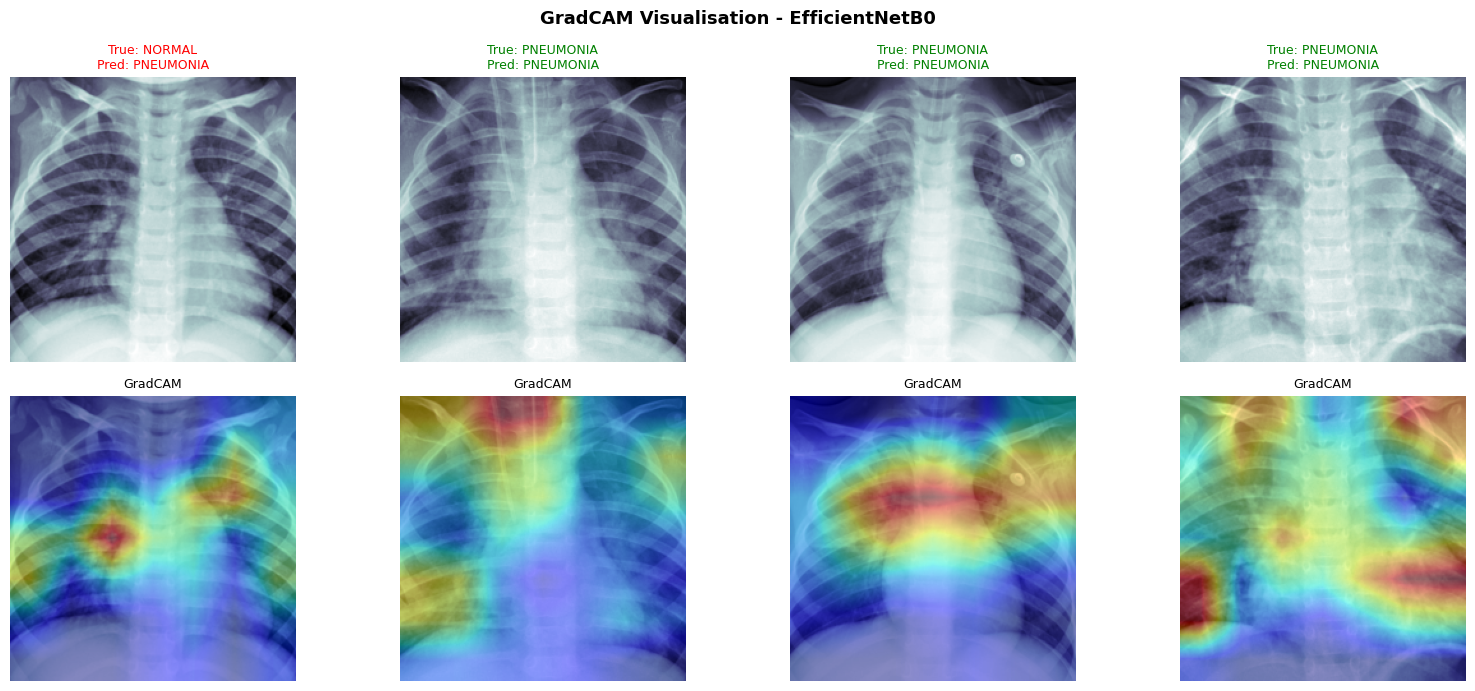

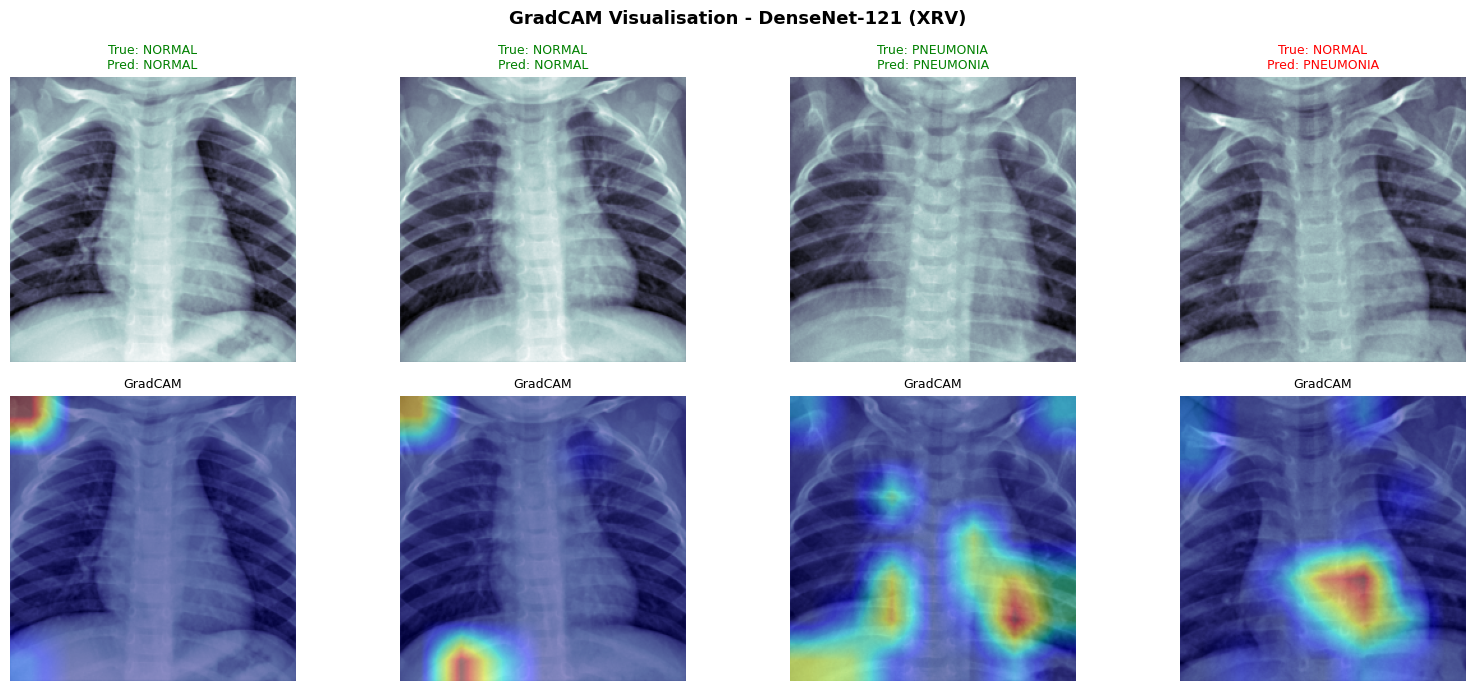

In [32]:
class GradCAM:
    """Minimal GradCAM for any model with a named target layer."""

    def __init__(self, model, target_layer):
        self.model = model
        self.gradients = None
        self.activations = None
        target_layer.register_forward_hook(self._save_activations)
        target_layer.register_full_backward_hook(self._save_gradients)

    def _save_activations(self, module, input, output):
        self.activations = output.detach()

    def _save_gradients(self, module, grad_in, grad_out):
        self.gradients = grad_out[0].detach()

    def generate(self, input_tensor, class_idx=None):
        self.model.eval()
        output = self.model(input_tensor)
        if output.dim() == 1:
            target = output[0]
        else:
            if class_idx is None:
                class_idx = output.argmax(dim=1).item()
            target = output[0, class_idx]
        self.model.zero_grad()
        target.backward()
        weights = self.gradients.mean(dim=[2, 3], keepdim=True)
        cam = (weights * self.activations).sum(dim=1, keepdim=True)
        cam = torch.relu(cam)
        cam = cam.squeeze().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        pred_idx = output.argmax(dim=1).item() if output.dim() > 1 else int(torch.sigmoid(output).item() >= 0.5)
        return cam, pred_idx


def show_gradcam(model, model_name, target_layer, dataset, device, model_type='softmax', n=4):
    import cv2
    gradcam = GradCAM(model, target_layer)
    indices = random.sample(range(len(dataset)), n)
    fig, axes = plt.subplots(2, n, figsize=(4*n, 7))

    for col, idx in enumerate(indices):
        img_tensor, label = dataset[idx]
        inp = img_tensor.unsqueeze(0).to(device)
        inp.requires_grad_(True)
        cam, pred_idx = gradcam.generate(inp)
        cam_resized = cv2.resize(cam, (224, 224))

        if model_type == 'softmax':
            mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
            std  = torch.tensor(IMAGENET_STD).view(3, 1, 1)
            orig = (img_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
            orig_gray = orig.mean(axis=2)
        else:
            orig = img_tensor.squeeze().numpy()
            orig_gray = (orig - orig.min()) / (orig.max() - orig.min() + 1e-8)

        correct = (label == pred_idx)
        axes[0, col].imshow(orig_gray, cmap='bone')
        axes[0, col].set_title(
            f'True: {dataset.classes[label]}\nPred: {dataset.classes[pred_idx]}',
            fontsize=9, color='green' if correct else 'red'
        )
        axes[0, col].axis('off')
        axes[1, col].imshow(orig_gray, cmap='bone')
        axes[1, col].imshow(cam_resized, cmap='jet', alpha=0.45)
        axes[1, col].set_title('GradCAM', fontsize=9)
        axes[1, col].axis('off')

    plt.suptitle(f'GradCAM Visualisation - {model_name}', fontsize=13, fontweight='bold')
    plt.tight_layout(); plt.show()


# ResNet50: last residual block
show_gradcam(resnet_model, 'ResNet50',
             target_layer=resnet_model.layer4[-1],
             dataset=test_dataset, device=DEVICE, model_type='softmax')

# EfficientNetB0: last features block
show_gradcam(effnet_model, 'EfficientNetB0',
             target_layer=effnet_model.features[-1],
             dataset=test_dataset, device=DEVICE, model_type='softmax')

# DenseNet-121 XRV: last dense block
show_gradcam(densenet_model, 'DenseNet-121 (XRV)',
             target_layer=densenet_model.backbone.features.denseblock4,
             dataset=test_dataset_xrv, device=DEVICE, model_type='sigmoid')


Looking at the heatmaps above, attention distributed across the central lung region is a reassuring sign. Attention concentrated on corners, image borders, or the area outside the lungs would suggest the model is responding to image formatting rather than clinical content. This concern is most relevant for ResNet50 and EfficientNetB0, which learned chest X-ray features entirely through fine-tuning on a single-source dataset and may have picked up formatting artifacts specific to this collection.


---
## 12. Final Conclusion and Limitations

### Summary

This notebook compared three transfer learning approaches for binary pneumonia classification from chest X-ray images. The workflow covered: dataset inspection and EDA, construction of a reliable stratified 80/20 validation split from the training folder, two preprocessing pipelines matched to each pretrained model's input format, two-phase fine-tuning with early stopping, three threshold strategies selected on the validation set, and a single final evaluation on the untouched test set.

### Key Result

**The final selected model is DenseNet-121 XRV with partial fine-tuning and Strategy C.**

For DenseNet, Strategy A and Strategy C select the same threshold in this run. I still report Strategy C as the final balanced choice because MCC is the more appropriate selection rule for an imbalanced binary classification problem. Strategy C is selected as the best balanced operating point because it gives the strongest MCC, highest accuracy, best NORMAL recall, and lowest false-positive count among the main models, while still maintaining high PNEUMONIA recall.

A likely reason for DenseNet's stronger thresholded performance is its domain-specific XRV pretraining. Since this model was pretrained on chest X-ray datasets, its earlier layers may already capture useful radiology-related texture and structure patterns before task-specific fine-tuning. This gives it a more suitable starting point than the ImageNet-pretrained models, although this explanation would need further testing to be confirmed.

### Screening Alternative

**Strategy B** is the better choice when minimizing missed PNEUMONIA-labeled cases is the priority. It guarantees PNEUMONIA recall ≥ 0.97 on the validation set, but accepts more false positives as a result. Whether Strategy B or C is more appropriate depends on the application context and the relative cost assigned to each error type. This choice cannot be decided by model metrics alone.

### Ensemble and TTA

The ensemble of ResNet50 and DenseNet-121 XRV achieved the highest AUROC and AUPRC among all approaches. This confirms that the two models capture at least some complementary information. However, the ensemble did not outperform DenseNet-121 XRV in thresholded classification - it produced more false positives and a lower MCC than DenseNet Strategy C. Equal-weight averaging improved ranking but not the final classifier.

TTA improved AUROC and AUPRC for ResNet50 compared to standard inference. Thresholded metrics did not substantially improve because the threshold was selected on non-TTA validation probabilities. TTA should be understood as a stability and ranking improvement; to use it properly in a deployment setting, thresholds would need to be re-selected on TTA-transformed validation predictions.

### Limitations

- **Single data source.** The dataset comes from one pediatric hospital. The model may not generalize to images from different scanners, patient populations, or acquisition protocols.
- **Train/test class-proportion mismatch.** PNEUMONIA accounts for ~74.3% of the training/validation pool but only 62.5% of the official test set. Thresholds selected on the more-imbalanced validation data may be slightly biased toward over-predicting PNEUMONIA on the test set.
- **No external validation.** Results are reported only on the Kermany test set. A more robust evaluation would use an independent dataset from a different institution.
- **No radiologist review.** The false-positive/false-negative image grids and GradCAM heatmaps were not reviewed by a trained radiologist. Any visual interpretation is a hypothesis, not a clinical finding.
- **Threshold choice is context-dependent.** The optimal FN/FP trade-off depends on downstream care pathways, follow-up availability, and patient risk levels - factors that a single validation metric cannot capture.
- **Pneumonia subtype not modeled.** Bacterial and viral pneumonia have different imaging presentations and different treatments. The dataset does not distinguish between them.
- **Single random seed.** All results use seed 42. Reporting performance over multiple seeds and splits would give a more reliable picture of variability.
- **Limited ensemble exploration.** Only equal-weight uncalibrated averaging was tested. Calibrated or weighted ensembles may perform differently.

### Future Work

- External validation on data from a different institution or scanner type
- Probability calibration (temperature scaling or Platt scaling) before threshold selection and ensembling
- Weighted or learned ensemble combination after calibration
- Radiologist review of failure cases and GradCAM outputs to identify systematic error patterns
- Cross-validation with multiple splits and seeds for more reliable performance estimates
- Subtype-aware modeling if labeled data distinguishing bacterial from viral pneumonia becomes available
